In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [3]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders:")
print(os.listdir())

Current working directory:
E:\datamites project\Hardest capstone 4\Riceleaf

Files and folders:
['.ipynb_checkpoints', 'leaf photos', 'PRCP-1001-RiceLeaf.docx', 'Untitled.ipynb', '~$CP-1001-RiceLeaf.docx']


In [4]:
dataset_path = "leaf photos"

print("Contents of dataset folder:\n")

for item in os.listdir(dataset_path):
    item_path = os.path.join(dataset_path, item)

    if os.path.isdir(item_path):
        print(f"Folder: {item}")
        print(f"Number of files: {len(os.listdir(item_path))}")
        print("-------------------------")
    else:
        print(f"File: {item}")

Contents of dataset folder:

Folder: Data
Number of files: 3
-------------------------


In [5]:
data_path = os.path.join(dataset_path, "Data")

print("Contents of Data folder:\n")

for item in os.listdir(data_path):
    item_path = os.path.join(data_path, item)

    if os.path.isdir(item_path):
        print(f"Class: {item}")
        print(f"Number of files: {len(os.listdir(item_path))}")
        print("-------------------------")

Contents of Data folder:

Class: Bacterial leaf blight-20200814T055237Z-001
Number of files: 1
-------------------------
Class: Brown spot-20200814T055208Z-001
Number of files: 1
-------------------------
Class: Leaf smut-20200814T055530Z-001
Number of files: 1
-------------------------


In [6]:
for root, dirs, files in os.walk(data_path):
    print("\nFolder:", root)
    print("Subfolders:", dirs)
    print("Number of files:", len(files))

    if files:
        print("Sample filenames:", files[:5])


Folder: leaf photos\Data
Subfolders: ['Bacterial leaf blight-20200814T055237Z-001', 'Brown spot-20200814T055208Z-001', 'Leaf smut-20200814T055530Z-001']
Number of files: 0

Folder: leaf photos\Data\Bacterial leaf blight-20200814T055237Z-001
Subfolders: ['Bacterial leaf blight']
Number of files: 0

Folder: leaf photos\Data\Bacterial leaf blight-20200814T055237Z-001\Bacterial leaf blight
Subfolders: []
Number of files: 40
Sample filenames: ['DSC_0365.JPG', 'DSC_0366.jpg', 'DSC_0367.JPG', 'DSC_0370.jpg', 'DSC_0372.JPG']

Folder: leaf photos\Data\Brown spot-20200814T055208Z-001
Subfolders: ['Brown spot']
Number of files: 0

Folder: leaf photos\Data\Brown spot-20200814T055208Z-001\Brown spot
Subfolders: []
Number of files: 40
Sample filenames: ['DSC_0100.jpg', 'DSC_0101.jpg', 'DSC_0104.jpg', 'DSC_0105.jpg', 'DSC_0106.jpg']

Folder: leaf photos\Data\Leaf smut-20200814T055530Z-001
Subfolders: ['Leaf smut']
Number of files: 0

Folder: leaf photos\Data\Leaf smut-20200814T055530Z-001\Leaf smut


In [7]:
class_paths = {
    "Bacterial Leaf Blight": os.path.join(
        data_path,
        "Bacterial leaf blight-20200814T055237Z-001",
        "Bacterial leaf blight"
    ),

    "Brown Spot": os.path.join(
        data_path,
        "Brown spot-20200814T055208Z-001",
        "Brown spot"
    ),

    "Leaf Smut": os.path.join(
        data_path,
        "Leaf smut-20200814T055530Z-001",
        "Leaf smut"
    )
}

for class_name, folder_path in class_paths.items():
    images = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg"))
    ]

    print(f"{class_name}: {len(images)} images")

Bacterial Leaf Blight: 40 images
Brown Spot: 40 images
Leaf Smut: 39 images


In [8]:
image_details = []

for class_name, folder_path in class_paths.items():
    for filename in os.listdir(folder_path):
        if filename.lower().endswith((".jpg", ".jpeg")):
            image_path = os.path.join(folder_path, filename)

            with Image.open(image_path) as img:
                image_details.append({
                    "Class": class_name,
                    "Filename": filename,
                    "Width": img.width,
                    "Height": img.height,
                    "Format": img.format,
                    "Mode": img.mode
                })

image_df = pd.DataFrame(image_details)

print("Total images:", len(image_df))
print("\nImage dimensions:")
print(image_df[["Width", "Height"]].describe())

print("\nImage formats:")
print(image_df["Format"].value_counts())

print("\nColor modes:")
print(image_df["Mode"].value_counts())

Total images: 119

Image dimensions:
             Width      Height
count   119.000000  119.000000
mean   2383.638655  707.739496
std    1123.528972  311.657582
min     250.000000   71.000000
25%    1074.000000  377.000000
50%    3081.000000  897.000000
75%    3081.000000  897.000000
max    3081.000000  900.000000

Image formats:
Format
JPEG    119
Name: count, dtype: int64

Color modes:
Mode
RGB    119
Name: count, dtype: int64


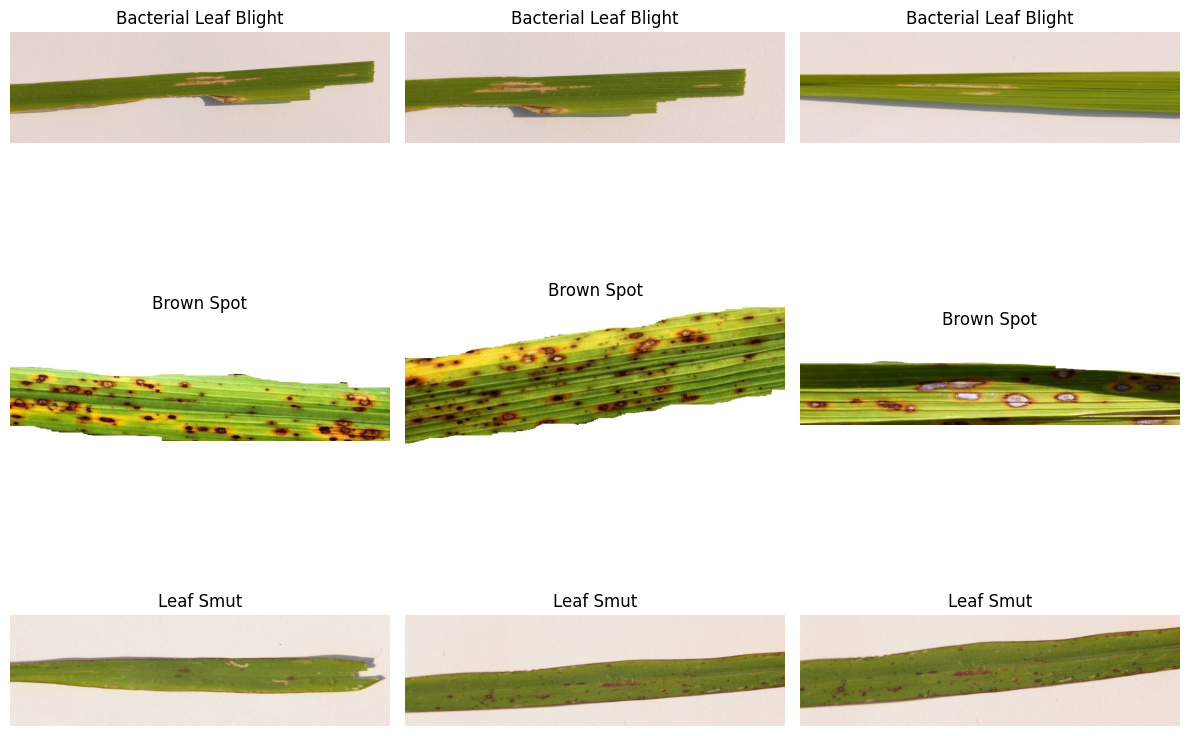

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(12, 10))

for row, (class_name, folder_path) in enumerate(class_paths.items()):

    image_files = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg"))
    ]

    for col in range(3):
        image_path = os.path.join(folder_path, image_files[col])

        img = Image.open(image_path)

        axes[row, col].imshow(img)
        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

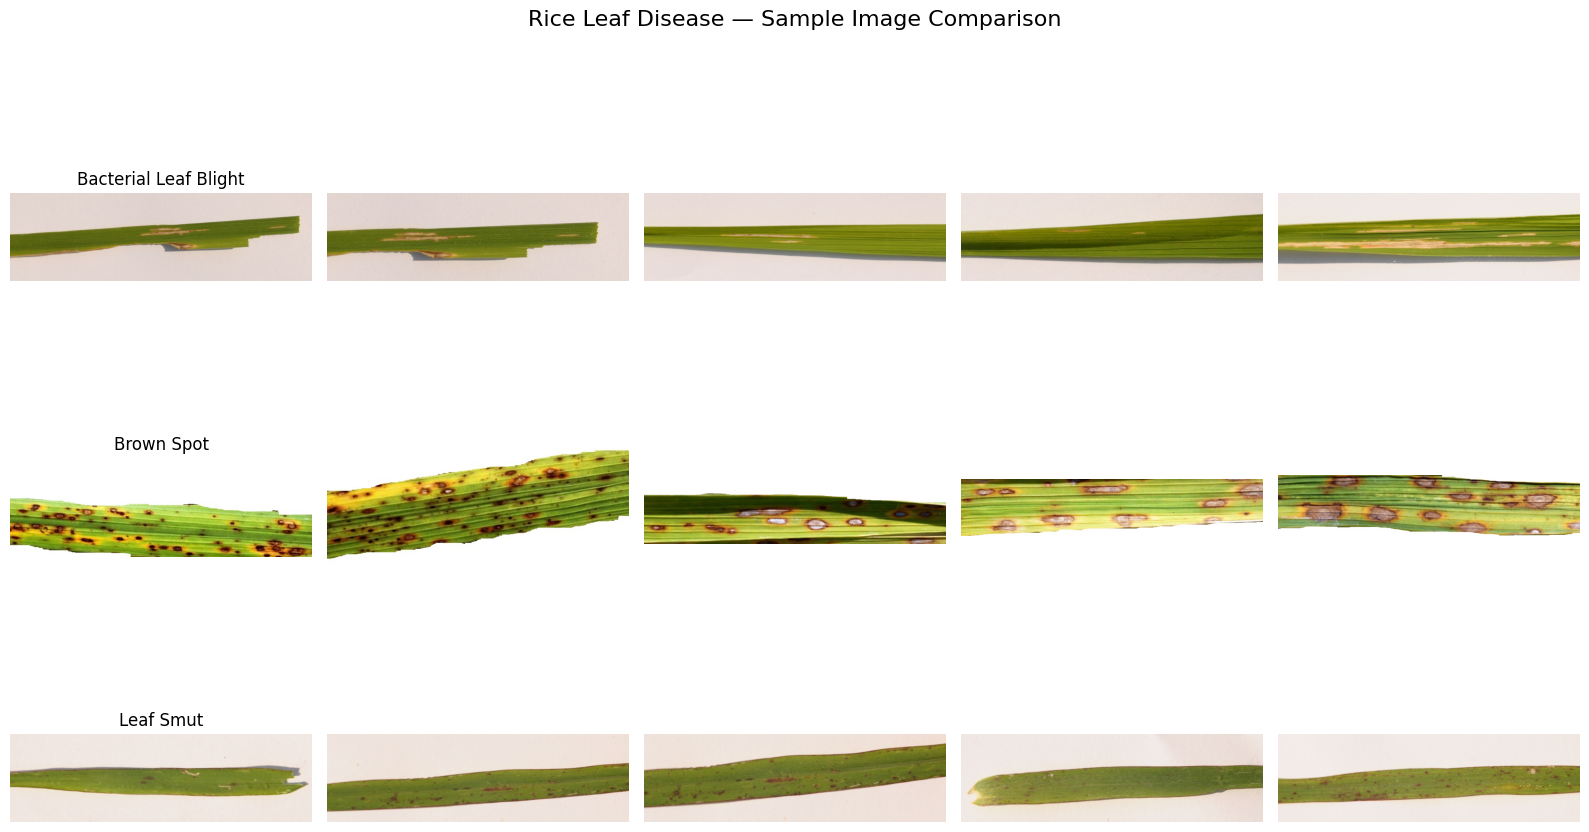

In [10]:
fig, axes = plt.subplots(3, 5, figsize=(16, 10))

for row, (class_name, folder_path) in enumerate(class_paths.items()):

    image_files = sorted([
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg"))
    ])

    for col in range(5):
        image_path = os.path.join(folder_path, image_files[col])

        with Image.open(image_path) as img:
            axes[row, col].imshow(img.copy())

        axes[row, col].set_title(class_name if col == 0 else "")
        axes[row, col].axis("off")

plt.suptitle("Rice Leaf Disease — Sample Image Comparison", fontsize=16)
plt.tight_layout()
plt.show()

In [11]:
image_stats = []

for class_name, folder_path in class_paths.items():

    for filename in os.listdir(folder_path):

        if filename.lower().endswith((".jpg", ".jpeg")):

            image_path = os.path.join(folder_path, filename)

            with Image.open(image_path) as img:
                img_array = np.array(img)

            image_stats.append({
                "Class": class_name,
                "Filename": filename,
                "Mean Brightness": np.mean(img_array),
                "Red Mean": np.mean(img_array[:, :, 0]),
                "Green Mean": np.mean(img_array[:, :, 1]),
                "Blue Mean": np.mean(img_array[:, :, 2])
            })

stats_df = pd.DataFrame(image_stats)

stats_df.head()

,Class,Filename,Mean Brightness,Red Mean,Green Mean,Blue Mean
0,Bacterial Leaf Blight,DSC_0365.JPG,182.677068,196.812530,187.389357,163.829316
1,Bacterial Leaf Blight,DSC_0366.jpg,179.508966,194.011853,185.148399,159.366644
2,Bacterial Leaf Blight,DSC_0367.JPG,180.357116,196.324843,189.773938,154.972565
3,Bacterial Leaf Blight,DSC_0370.jpg,159.212224,174.996505,171.419818,131.220349
4,Bacterial Leaf Blight,DSC_0372.JPG,173.493522,190.699627,186.265722,143.515217


In [12]:
class_summary = stats_df.groupby("Class")[
    ["Mean Brightness", "Red Mean", "Green Mean", "Blue Mean"]
].mean().round(2)

print(class_summary)

                       Mean Brightness  Red Mean  Green Mean  Blue Mean
Class                                                                  
Bacterial Leaf Blight           178.43    194.20      188.88     152.22
Brown Spot                      169.13    191.29      189.45     126.66
Leaf Smut                       167.82    180.11      181.93     141.42


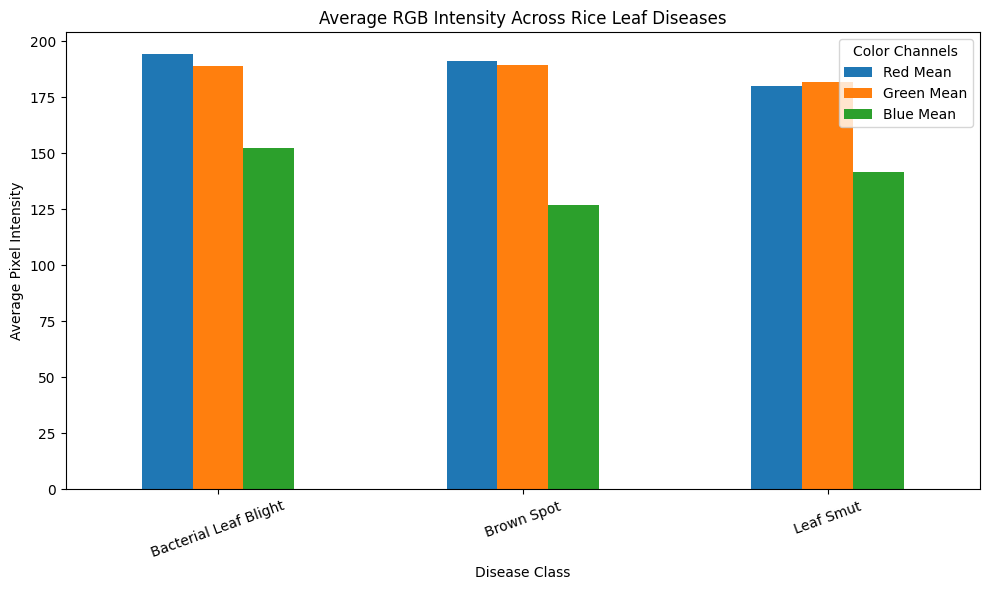

In [13]:
color_columns = ["Red Mean", "Green Mean", "Blue Mean"]

class_summary[color_columns].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Average RGB Intensity Across Rice Leaf Diseases")
plt.xlabel("Disease Class")
plt.ylabel("Average Pixel Intensity")
plt.xticks(rotation=20)
plt.legend(title="Color Channels")
plt.tight_layout()
plt.show()

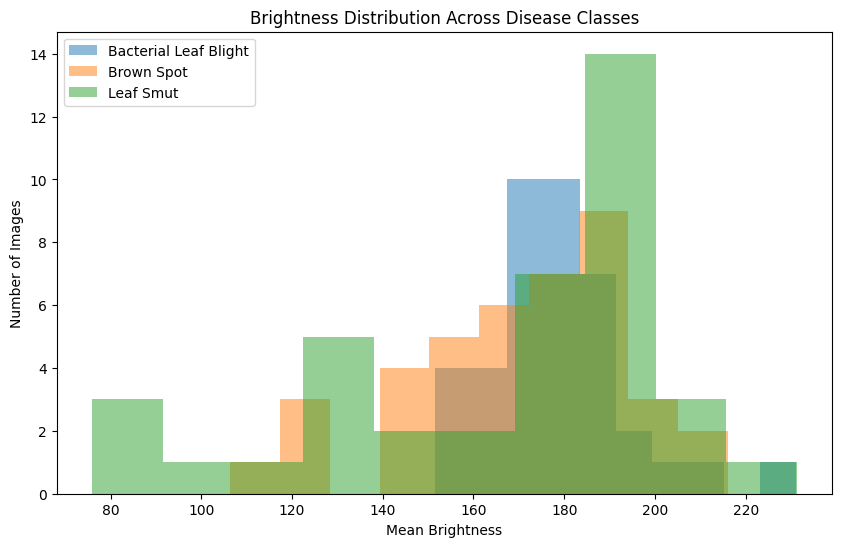

In [14]:
plt.figure(figsize=(10, 6))

for class_name in stats_df["Class"].unique():

    class_data = stats_df[
        stats_df["Class"] == class_name
    ]["Mean Brightness"]

    plt.hist(
        class_data,
        bins=10,
        alpha=0.5,
        label=class_name
    )

plt.title("Brightness Distribution Across Disease Classes")
plt.xlabel("Mean Brightness")
plt.ylabel("Number of Images")
plt.legend()
plt.show()

## Check image quality

In [15]:
!pip install opencv-python

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.5/44.0 MB 1.6 MB/s eta 0:00:27
    --------------------------------------- 0.8/44.0 MB 1.7 MB/s eta 0:00:26
    --------------------------------------- 1.0/44.0 MB 1.5 MB/s eta 0:00:29
   - -------------------------------------- 1.6/44.0 MB 1.6 MB/s eta 0:00:27
   - -------------------------------------- 2.1/44.0 MB 1.9 MB/s eta 0:00:23
   -- ------------------------------------- 2.9/44.0 MB 2.2 MB/s eta 0:00:20
   -- ------------------------------------- 2.9/44.0 MB 2.2 MB/s eta 0:00:20
   -- ------------------------------------- 3.1/44.0 MB 1.9 MB/s eta 0:00:22
   --- -------------------

In [16]:
import cv2

sharpness_data = []

for class_name, folder_path in class_paths.items():

    for filename in os.listdir(folder_path):

        if filename.lower().endswith((".jpg", ".jpeg")):

            image_path = os.path.join(folder_path, filename)

            image = cv2.imread(image_path)
            gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

            sharpness = cv2.Laplacian(
                gray_image,
                cv2.CV_64F
            ).var()

            sharpness_data.append({
                "Class": class_name,
                "Filename": filename,
                "Sharpness": sharpness
            })

sharpness_df = pd.DataFrame(sharpness_data)

print(sharpness_df.groupby("Class")["Sharpness"].describe().round(2))

                       count    mean     std   min    25%    50%     75%  \
Class                                                                      
Bacterial Leaf Blight   40.0   25.07   26.65  3.46  10.92  17.62   27.33   
Brown Spot              40.0  228.28  270.76  4.73   7.26  52.44  394.82   
Leaf Smut               39.0  266.87  391.69  5.15   8.21  14.08  539.49   

                           max  
Class                           
Bacterial Leaf Blight   149.94  
Brown Spot              881.14  
Leaf Smut              1315.80  


In [17]:
print(
    sharpness_df.sort_values("Sharpness").head(10)
)

                    Class      Filename  Sharpness
38  Bacterial Leaf Blight  DSC_0702.jpg   3.456036
61             Brown Spot  DSC_0296.jpg   4.730288
98              Leaf Smut  DSC_0331.JPG   5.145564
39  Bacterial Leaf Blight  DSC_0703.JPG   5.312137
64             Brown Spot  DSC_0301.JPG   5.376407
76             Brown Spot  DSC_0333.JPG   5.577566
72             Brown Spot  DSC_0324.JPG   5.618950
62             Brown Spot  DSC_0299.JPG   5.674554
63             Brown Spot  DSC_0300.JPG   5.715393
99              Leaf Smut  DSC_0335.JPG   5.815433


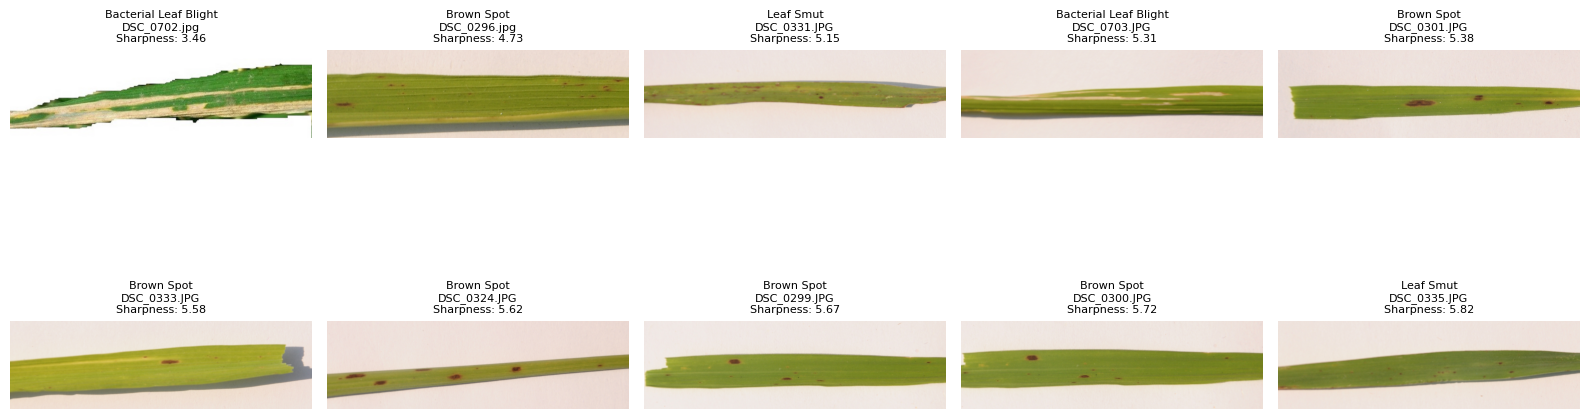

In [18]:
lowest_images = sharpness_df.nsmallest(10, "Sharpness")

fig, axes = plt.subplots(2, 5, figsize=(16, 7))

for ax, (_, row) in zip(axes.flat, lowest_images.iterrows()):

    image_path = os.path.join(
        class_paths[row["Class"]],
        row["Filename"]
    )

    with Image.open(image_path) as img:
        ax.imshow(img.copy())

    ax.set_title(
        f'{row["Class"]}\n{row["Filename"]}\nSharpness: {row["Sharpness"]:.2f}',
        fontsize=8
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [19]:
import hashlib

image_hashes = []

for class_name, folder_path in class_paths.items():

    for filename in os.listdir(folder_path):

        if filename.lower().endswith((".jpg", ".jpeg")):

            image_path = os.path.join(folder_path, filename)

            with open(image_path, "rb") as file:
                file_hash = hashlib.md5(file.read()).hexdigest()

            image_hashes.append({
                "Class": class_name,
                "Filename": filename,
                "Hash": file_hash
            })

hash_df = pd.DataFrame(image_hashes)

print("Total images:", len(hash_df))
print("Unique images:", hash_df["Hash"].nunique())
print("Duplicate images:", hash_df["Hash"].duplicated().sum())

Total images: 119
Unique images: 119
Duplicate images: 0


In [20]:
dataset_summary = []

for class_name, folder_path in class_paths.items():

    image_files = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg"))
    ]

    dataset_summary.append({
        "Disease Class": class_name,
        "Image Count": len(image_files),
        "Percentage": round(
            len(image_files) / len(hash_df) * 100, 2
        )
    })

dataset_summary_df = pd.DataFrame(dataset_summary)

print(dataset_summary_df.to_string(index=False))

print("\nTotal images:", dataset_summary_df["Image Count"].sum())

        Disease Class  Image Count  Percentage
Bacterial Leaf Blight           40       33.61
           Brown Spot           40       33.61
            Leaf Smut           39       32.77

Total images: 119


In [21]:
for class_name, folder_path in class_paths.items():

    filenames = sorted([
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg"))
    ])

    print(f"\n{class_name}")
    print("First 10:", filenames[:10])
    print("Last 10:", filenames[-10:])


Bacterial Leaf Blight
First 10: ['DSC_0365.JPG', 'DSC_0366.jpg', 'DSC_0367.JPG', 'DSC_0370.jpg', 'DSC_0372.JPG', 'DSC_0373.JPG', 'DSC_0374.JPG', 'DSC_0375.JPG', 'DSC_0376.JPG', 'DSC_0377.JPG']
Last 10: ['DSC_0401.JPG', 'DSC_0402.JPG', 'DSC_0403.JPG', 'DSC_0404.JPG', 'DSC_0405.JPG', 'DSC_0406.JPG', 'DSC_0700.jpg', 'DSC_0701.jpg', 'DSC_0702.jpg', 'DSC_0703.JPG']

Brown Spot
First 10: ['DSC_0100.jpg', 'DSC_0101.jpg', 'DSC_0104.jpg', 'DSC_0105.jpg', 'DSC_0106.jpg', 'DSC_0107.jpg', 'DSC_0108.jpg', 'DSC_0109.jpg', 'DSC_0110.jpg', 'DSC_0111.jpg']
Last 10: ['DSC_0307.JPG', 'DSC_0323.JPG', 'DSC_0324.JPG', 'DSC_0325.JPG', 'DSC_0329.jpg', 'DSC_0332.JPG', 'DSC_0333.JPG', 'DSC_0337.JPG', 'DSC_0391.jpg', 'DSC_0394.jpg']

Leaf Smut
First 10: ['DSC_0293.JPG', 'DSC_0308.JPG', 'DSC_0309.JPG', 'DSC_0310.JPG', 'DSC_0312.JPG', 'DSC_0313.JPG', 'DSC_0314.JPG', 'DSC_0315.jpg', 'DSC_0316.JPG', 'DSC_0317.JPG']
Last 10: ['DSC_0506.jpg', 'DSC_0507.jpg', 'DSC_0509.jpg', 'DSC_0510.jpg', 'DSC_0511.jpg', 'DSC_0512.j

In [22]:
import re

filename_numbers = {}

for class_name, folder_path in class_paths.items():

    numbers = set()

    for filename in os.listdir(folder_path):

        if filename.lower().endswith((".jpg", ".jpeg")):

            match = re.search(r"DSC_(\d+)", filename, re.IGNORECASE)

            if match:
                numbers.add(int(match.group(1)))

    filename_numbers[class_name] = numbers


classes = list(filename_numbers.keys())

for i in range(len(classes)):
    for j in range(i + 1, len(classes)):

        class_a = classes[i]
        class_b = classes[j]

        overlap = filename_numbers[class_a].intersection(
            filename_numbers[class_b]
        )

        print(f"\n{class_a} vs {class_b}")
        print("Overlapping filename numbers:", sorted(overlap))
        print("Number of overlaps:", len(overlap))


Bacterial Leaf Blight vs Brown Spot
Overlapping filename numbers: []
Number of overlaps: 0

Bacterial Leaf Blight vs Leaf Smut
Overlapping filename numbers: []
Number of overlaps: 0

Brown Spot vs Leaf Smut
Overlapping filename numbers: []
Number of overlaps: 0


In [23]:
corrupted_images = []

for class_name, folder_path in class_paths.items():

    for filename in os.listdir(folder_path):

        if filename.lower().endswith((".jpg", ".jpeg")):

            image_path = os.path.join(folder_path, filename)

            try:
                with Image.open(image_path) as img:
                    img.verify()

            except Exception as error:
                corrupted_images.append({
                    "Class": class_name,
                    "Filename": filename,
                    "Error": str(error)
                })

print("Total corrupted images:", len(corrupted_images))

if corrupted_images:
    print(pd.DataFrame(corrupted_images).to_string(index=False))
else:
    print("All images passed the integrity check.")

Total corrupted images: 0
All images passed the integrity check.


In [24]:
image_df["Aspect Ratio"] = (
    image_df["Width"] / image_df["Height"]
)

print(
    image_df["Aspect Ratio"].describe().round(2)
)

print("\nImages with the smallest aspect ratios:")
print(
    image_df.nsmallest(5, "Aspect Ratio")[
        ["Class", "Filename", "Width", "Height", "Aspect Ratio"]
    ].to_string(index=False)
)

print("\nImages with the largest aspect ratios:")
print(
    image_df.nlargest(5, "Aspect Ratio")[
        ["Class", "Filename", "Width", "Height", "Aspect Ratio"]
    ].to_string(index=False)
)

count    119.00
mean       3.33
std        0.65
min        1.25
25%        3.43
50%        3.43
75%        3.43
max        5.30
Name: Aspect Ratio, dtype: float64

Images with the smallest aspect ratios:
     Class     Filename  Width  Height  Aspect Ratio
 Leaf Smut DSC_0504.jpg    250     200      1.250000
 Leaf Smut DSC_0512.jpg    250     200      1.250000
 Leaf Smut DSC_0513.jpg    510     383      1.331593
Brown Spot DSC_0121.jpg   1200     900      1.333333
Brown Spot DSC_0113.jpg    768     514      1.494163

Images with the largest aspect ratios:
     Class     Filename  Width  Height  Aspect Ratio
Brown Spot DSC_0105.jpg   1480     279      5.304659
 Leaf Smut DSC_0501.jpg    367      73      5.027397
 Leaf Smut DSC_0500.jpg    376      80      4.700000
Brown Spot DSC_0106.jpg   1504     323      4.656347
 Leaf Smut DSC_0507.jpg    948     211      4.492891


In [25]:
dimension_summary = image_df.groupby("Class").agg(
    Image_Count=("Filename", "count"),
    Average_Width=("Width", "mean"),
    Average_Height=("Height", "mean"),
    Average_Aspect_Ratio=("Aspect Ratio", "mean"),
    Minimum_Width=("Width", "min"),
    Maximum_Width=("Width", "max")
)

print(dimension_summary.round(2))

                       Image_Count  Average_Width  Average_Height  \
Class                                                               
Bacterial Leaf Blight           40        3081.00          897.00   
Brown Spot                      40        1951.28          589.17   
Leaf Smut                       39        2111.85          635.23   

                       Average_Aspect_Ratio  Minimum_Width  Maximum_Width  
Class                                                                      
Bacterial Leaf Blight                  3.43           3081           3081  
Brown Spot                             3.28            286           3081  
Leaf Smut                              3.25            250           3081  


In [26]:
for class_name, folder_path in class_paths.items():

    dimensions = []

    for filename in os.listdir(folder_path):

        if filename.lower().endswith((".jpg", ".jpeg")):

            image_path = os.path.join(folder_path, filename)

            with Image.open(image_path) as img:
                dimensions.append(img.size)

    dimension_counts = pd.Series(dimensions).value_counts()

    print(f"\n{class_name}")
    print(dimension_counts.to_string())


Bacterial Leaf Blight
(3081, 897)    40

Brown Spot
(3081, 897)    21
(766, 250)      1
(617, 244)      1
(1530, 371)     1
(1480, 279)     1
(1504, 323)     1
(765, 224)      1
(763, 268)      1
(699, 197)      1
(456, 124)      1
(316, 127)      1
(427, 193)      1
(768, 514)      1
(296, 88)       1
(286, 92)       1
(340, 94)       1
(467, 104)      1
(359, 168)      1
(311, 170)      1
(1200, 900)     1

Leaf Smut
(3081, 897)    24
(250, 200)      2
(376, 80)       1
(367, 73)       1
(301, 71)       1
(614, 409)      1
(946, 255)      1
(948, 233)      1
(948, 211)      1
(537, 216)      1
(503, 174)      1
(510, 383)      1
(565, 233)      1
(562, 217)      1
(741, 291)      1


In [27]:
common_resolution = (3081, 897)

resolution_analysis = []

for class_name, folder_path in class_paths.items():

    total = 0
    common_count = 0

    for filename in os.listdir(folder_path):

        if filename.lower().endswith((".jpg", ".jpeg")):

            total += 1

            image_path = os.path.join(folder_path, filename)

            with Image.open(image_path) as img:

                if img.size == common_resolution:
                    common_count += 1

    resolution_analysis.append({
        "Class": class_name,
        "Total Images": total,
        "Common Resolution Images": common_count,
        "Other Resolution Images": total - common_count,
        "Common Resolution Percentage": round(
            common_count / total * 100, 2
        )
    })

resolution_analysis_df = pd.DataFrame(resolution_analysis)

print(resolution_analysis_df.to_string(index=False))

                Class  Total Images  Common Resolution Images  Other Resolution Images  Common Resolution Percentage
Bacterial Leaf Blight            40                        40                        0                        100.00
           Brown Spot            40                        21                       19                         52.50
            Leaf Smut            39                        24                       15                         61.54


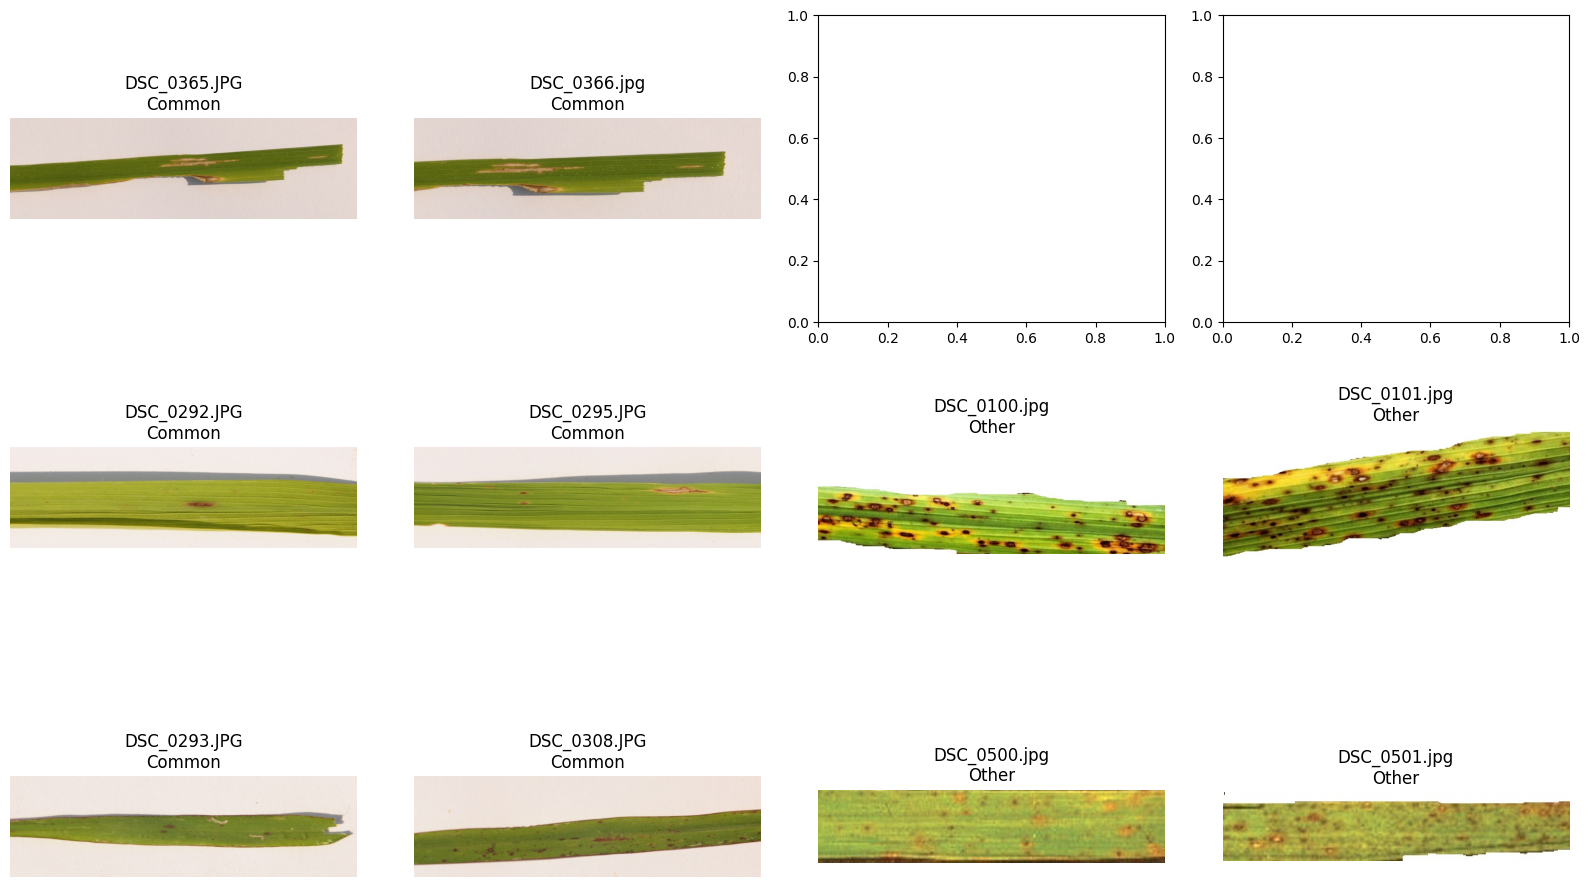

In [28]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))

for row, (class_name, folder_path) in enumerate(class_paths.items()):

    filenames = sorted([
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg"))
    ])

    common_files = []
    other_files = []

    for filename in filenames:

        image_path = os.path.join(folder_path, filename)

        with Image.open(image_path) as img:

            if img.size == (3081, 897):
                common_files.append(filename)
            else:
                other_files.append(filename)

    selected_files = (
        common_files[:2] + other_files[:2]
    )

    for col, filename in enumerate(selected_files):

        image_path = os.path.join(folder_path, filename)

        with Image.open(image_path) as img:
            axes[row, col].imshow(img)

        axes[row, col].set_title(
            f"{filename}\n"
            f"{'Common' if filename in common_files else 'Other'}"
        )

        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(class_name, fontsize=11)

plt.tight_layout()
plt.show()

## ### Dataset Quality and Potential Bias

The dataset contains 119 RGB JPEG images across three disease categories: Bacterial Leaf Blight (40), Brown Spot (40), and Leaf Smut (39).

The class distribution is approximately balanced. All images passed the integrity check, and no exact duplicate files or cross-class filename-number overlaps were identified.

However, image dimensions vary considerably. All 40 Bacterial Leaf Blight images have a resolution of 3081 × 897, whereas only 21 Brown Spot images and 24 Leaf Smut images share this resolution.

Visual inspection also revealed noticeable background differences between common-resolution and other-resolution images. No obvious difference in leaf framing was observed.

These findings indicate a potential dataset acquisition bias. A classification model could learn background or image-acquisition characteristics instead of disease-specific visual features.

To reduce this risk, images will undergo consistent preprocessing, and model evaluation will use stratified validation. Background-related shortcut learning will remain an important limitation when interpreting results.

All 119 images will be retained for further analysis.

In [29]:
dataset_records = []

for class_name, folder_path in class_paths.items():

    for filename in os.listdir(folder_path):

        if filename.lower().endswith((".jpg", ".jpeg")):

            image_path = os.path.join(folder_path, filename)

            with Image.open(image_path) as img:

                width, height = img.size

            dataset_records.append({
                "Filename": filename,
                "File_Path": image_path,
                "Class": class_name,
                "Width": width,
                "Height": height,
                "Aspect_Ratio": width / height,
                "File_Size_KB": round(
                    os.path.getsize(image_path) / 1024, 2
                )
            })

dataset_df = pd.DataFrame(dataset_records)

print("Dataset shape:", dataset_df.shape)
print("\nFirst five records:")
print(dataset_df.head().to_string(index=False))

Dataset shape: (119, 7)

First five records:
    Filename                                                                                      File_Path                 Class  Width  Height  Aspect_Ratio  File_Size_KB
DSC_0365.JPG leaf photos\Data\Bacterial leaf blight-20200814T055237Z-001\Bacterial leaf blight\DSC_0365.JPG Bacterial Leaf Blight   3081     897      3.434783        456.16
DSC_0366.jpg leaf photos\Data\Bacterial leaf blight-20200814T055237Z-001\Bacterial leaf blight\DSC_0366.jpg Bacterial Leaf Blight   3081     897      3.434783        408.13
DSC_0367.JPG leaf photos\Data\Bacterial leaf blight-20200814T055237Z-001\Bacterial leaf blight\DSC_0367.JPG Bacterial Leaf Blight   3081     897      3.434783        442.02
DSC_0370.jpg leaf photos\Data\Bacterial leaf blight-20200814T055237Z-001\Bacterial leaf blight\DSC_0370.jpg Bacterial Leaf Blight   3081     897      3.434783        418.68
DSC_0372.JPG leaf photos\Data\Bacterial leaf blight-20200814T055237Z-001\Bacterial leaf bl

In [30]:
print("Total records:", len(dataset_df))

print(
    "Existing image paths:",
    dataset_df["File_Path"].apply(os.path.exists).sum()
)

print(
    "Missing values:\n",
    dataset_df.isnull().sum()
)

print(
    "\nClass distribution:\n",
    dataset_df["Class"].value_counts()
)

Total records: 119
Existing image paths: 119
Missing values:
 Filename        0
File_Path       0
Class           0
Width           0
Height          0
Aspect_Ratio    0
File_Size_KB    0
dtype: int64

Class distribution:
 Class
Bacterial Leaf Blight    40
Brown Spot               40
Leaf Smut                39
Name: count, dtype: int64


In [31]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.22.0-rc0
GPU available: []


### Computing Environment

- Operating system: Windows (native)
- TensorFlow version: 2.22.0-rc0
- Hardware acceleration: CPU
- GPU availability: Not available

**Training consideration:** Since GPU acceleration is unavailable, initial experiments will use computationally efficient architectures and controlled training settings. More demanding experiments will be evaluated based on training time.

In [32]:
import sklearn
import tensorflow as tf
import numpy as np
import pandas as pd

print("TensorFlow:", tf.__version__)
print("Scikit-learn:", sklearn.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Keras:", tf.keras.__version__ if hasattr(tf.keras, "__version__") else "Available")

TensorFlow: 2.22.0-rc0
Scikit-learn: 1.9.0
NumPy: 2.4.2
Pandas: 3.0.3
Keras: 3.16.0.dev2026103103


In [33]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

dataset_df["Encoded_Class"] = label_encoder.fit_transform(
    dataset_df["Class"]
)

print("Class mapping:")

for index, class_name in enumerate(label_encoder.classes_):
    print(f"{class_name} = {index}")

print("\nUpdated dataset:")
print(
    dataset_df[
        ["Filename", "Class", "Encoded_Class"]
    ].head(10).to_string(index=False)
)

Class mapping:
Bacterial Leaf Blight = 0
Brown Spot = 1
Leaf Smut = 2

Updated dataset:
    Filename                 Class  Encoded_Class
DSC_0365.JPG Bacterial Leaf Blight              0
DSC_0366.jpg Bacterial Leaf Blight              0
DSC_0367.JPG Bacterial Leaf Blight              0
DSC_0370.jpg Bacterial Leaf Blight              0
DSC_0372.JPG Bacterial Leaf Blight              0
DSC_0373.JPG Bacterial Leaf Blight              0
DSC_0374.JPG Bacterial Leaf Blight              0
DSC_0375.JPG Bacterial Leaf Blight              0
DSC_0376.JPG Bacterial Leaf Blight              0
DSC_0377.JPG Bacterial Leaf Blight              0


## Cross fold validation

In [34]:
from sklearn.model_selection import StratifiedKFold

X = dataset_df["File_Path"].values
y = dataset_df["Encoded_Class"].values

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X, y), start=1
):

    print(f"\nFold {fold}")
    print("Training images:", len(train_idx))
    print("Validation images:", len(val_idx))

    print(
        "Training class distribution:",
        np.bincount(y[train_idx])
    )

    print(
        "Validation class distribution:",
        np.bincount(y[val_idx])
    )


Fold 1
Training images: 95
Validation images: 24
Training class distribution: [32 32 31]
Validation class distribution: [8 8 8]

Fold 2
Training images: 95
Validation images: 24
Training class distribution: [32 32 31]
Validation class distribution: [8 8 8]

Fold 3
Training images: 95
Validation images: 24
Training class distribution: [32 32 31]
Validation class distribution: [8 8 8]

Fold 4
Training images: 95
Validation images: 24
Training class distribution: [32 32 31]
Validation class distribution: [8 8 8]

Fold 5
Training images: 96
Validation images: 23
Training class distribution: [32 32 32]
Validation class distribution: [8 8 7]


In [35]:
folds = list(skf.split(X, y))

validation_counts = np.zeros(len(dataset_df), dtype=int)

for fold, (train_idx, val_idx) in enumerate(folds, start=1):

    validation_counts[val_idx] += 1

    print(
        f"Fold {fold}: "
        f"Train = {len(train_idx)}, "
        f"Validation = {len(val_idx)}"
    )

print("\nValidation appearances per image:")
print(pd.Series(validation_counts).value_counts().sort_index())

Fold 1: Train = 95, Validation = 24
Fold 2: Train = 95, Validation = 24
Fold 3: Train = 95, Validation = 24
Fold 4: Train = 95, Validation = 24
Fold 5: Train = 96, Validation = 23

Validation appearances per image:
1    119
Name: count, dtype: int64


In [36]:
IMG_SIZE = 224

def preprocess_image(image_path):

    image = tf.io.read_file(image_path)

    image = tf.io.decode_jpeg(
        image,
        channels=3
    )

    image = tf.image.resize_with_pad(
        image,
        target_height=IMG_SIZE,
        target_width=IMG_SIZE
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image

In [37]:
sample_image = preprocess_image(X[0])

print("Image shape:", sample_image.shape)
print("Data type:", sample_image.dtype)
print("Minimum pixel value:", tf.reduce_min(sample_image).numpy())
print("Maximum pixel value:", tf.reduce_max(sample_image).numpy())

Image shape: (224, 224, 3)
Data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 0.94155896


In [38]:
sample_images = []

for image_path in X:

    image = preprocess_image(image_path)

    sample_images.append(image)

sample_images = tf.stack(sample_images)

print("Complete image tensor shape:", sample_images.shape)
print("Data type:", sample_images.dtype)
print(
    "All values finite:",
    tf.reduce_all(tf.math.is_finite(sample_images)).numpy()
)

Complete image tensor shape: (119, 224, 224, 3)
Data type: <dtype: 'float32'>
All values finite: True


In [39]:
# Convert encoded labels into a TensorFlow tensor

labels_tensor = tf.convert_to_tensor(
    y,
    dtype=tf.int32
)

# Check image and label counts

print("Images shape:", sample_images.shape)
print("Labels shape:", labels_tensor.shape)

# Display the first 10 labels

print("First 10 encoded labels:", labels_tensor[:10].numpy())

# Display the class mapping

print("Class mapping:", dict(
    enumerate(label_encoder.classes_)
))

Images shape: (119, 224, 224, 3)
Labels shape: (119,)
First 10 encoded labels: [0 0 0 0 0 0 0 0 0 0]
Class mapping: {0: 'Bacterial Leaf Blight', 1: 'Brown Spot', 2: 'Leaf Smut'}


In [40]:
# Create a TensorFlow dataset from images and labels

dataset = tf.data.Dataset.from_tensor_slices(
    (sample_images, labels_tensor)
)

# Shuffle the dataset

dataset = dataset.shuffle(
    buffer_size=len(sample_images),
    seed=42
)

# Divide data into batches of 16

dataset = dataset.batch(16)

# Improve data-loading performance

dataset = dataset.prefetch(
    tf.data.AUTOTUNE
)

# Inspect the dataset

for images, labels in dataset.take(1):

    print("Batch image shape:", images.shape)
    print("Batch label shape:", labels.shape)
    print("Labels in batch:", labels.numpy())

Batch image shape: (16, 224, 224, 3)
Batch label shape: (16,)
Labels in batch: [1 1 0 1 2 0 2 1 1 1 2 0 2 0 2 1]


In [41]:
# Get training and validation indices for Fold 1

train_idx, val_idx = folds[0]

# Extract training and validation images

X_train = sample_images.numpy()[train_idx]
X_val = sample_images.numpy()[val_idx]

# Extract corresponding labels

y_train = y[train_idx]
y_val = y[val_idx]

# Display dataset sizes

print("Training images:", X_train.shape)
print("Validation images:", X_val.shape)

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nValidation class distribution:")
print(pd.Series(y_val).value_counts().sort_index())

Training images: (95, 224, 224, 3)
Validation images: (24, 224, 224, 3)

Training class distribution:
0    32
1    32
2    31
Name: count, dtype: int64

Validation class distribution:
0    8
1    8
2    8
Name: count, dtype: int64


## Building CNN


In [42]:
from tensorflow.keras import layers, models

def build_cnn():

    model = models.Sequential([

        layers.Input(shape=(224, 224, 3)),

        layers.Conv2D(
            32,
            (3, 3),
            activation="relu"
        ),

        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(
            64,
            (3, 3),
            activation="relu"
        ),

        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),

        layers.Dense(
            128,
            activation="relu"
        ),

        layers.Dropout(0.5),

        layers.Dense(
            3,
            activation="softmax"
        )
    ])

    return model


cnn_model = build_cnn()

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 186624)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      23,888,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,907,779 (91.20 MB)

 Trainable params: 23,907,779 (91.20 MB)

 Non-trainable params: 0 (0.00 B)

In [43]:
from tensorflow.keras import layers, models

def build_cnn():

    model = models.Sequential([

        layers.Input(shape=(224, 224, 3)),

        layers.Conv2D(
            32,
            (3, 3),
            activation="relu"
        ),

        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(
            64,
            (3, 3),
            activation="relu"
        ),

        layers.MaxPooling2D((2, 2)),

        layers.GlobalAveragePooling2D(),

        layers.Dense(
            64,
            activation="relu"
        ),

        layers.Dropout(0.5),

        layers.Dense(
            3,
            activation="softmax"
        )
    ])

    return model


cnn_model = build_cnn()

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)                    │ (None, 222, 222, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 64)                  │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 3)                   │             195 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,747 (92.76 KB)

 Trainable params: 23,747 (92.76 KB)

 Non-trainable params: 0 (0.00 B)

In [44]:
cnn_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [45]:
data_augmentation = tf.keras.Sequential([

    layers.RandomFlip(
        mode="horizontal"
    ),

    layers.RandomRotation(
        factor=0.1
    ),

    layers.RandomZoom(
        height_factor=0.1,
        width_factor=0.1
    )

])

print("Data augmentation pipeline created!")

Data augmentation pipeline created!


In [46]:
def build_augmented_cnn():

    model = models.Sequential([

        layers.Input(shape=(224, 224, 3)),

        # Apply augmentation during training
        data_augmentation,

        # Feature extraction
        layers.Conv2D(
            32,
            (3, 3),
            activation="relu"
        ),

        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(
            64,
            (3, 3),
            activation="relu"
        ),

        layers.MaxPooling2D((2, 2)),

        # Feature reduction
        layers.GlobalAveragePooling2D(),

        # Classification
        layers.Dense(
            64,
            activation="relu"
        ),

        layers.Dropout(0.5),

        layers.Dense(
            3,
            activation="softmax"
        )
    ])

    return model


augmented_cnn = build_augmented_cnn()

augmented_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

augmented_cnn.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)            │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 222, 222, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 64)                  │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 3)                   │             195 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,747 (92.76 KB)

 Trainable params: 23,747 (92.76 KB)

 Non-trainable params: 0 (0.00 B)

In [47]:
# Select one training image
test_image = X_train[0]

# Add a batch dimension
test_image_batch = tf.expand_dims(test_image, axis=0)

# Apply augmentation twice
augmented_image_1 = data_augmentation(
    test_image_batch,
    training=True
)

augmented_image_2 = data_augmentation(
    test_image_batch,
    training=True
)

# Calculate differences
difference_1 = tf.reduce_mean(
    tf.abs(test_image_batch - augmented_image_1)
)

difference_2 = tf.reduce_mean(
    tf.abs(test_image_batch - augmented_image_2)
)

print("Original image shape:", test_image_batch.shape)

print(
    "Difference after augmentation 1:",
    difference_1.numpy()
)

print(
    "Difference after augmentation 2:",
    difference_2.numpy()
)

Original image shape: (1, 224, 224, 3)
Difference after augmentation 1: 0.27096066
Difference after augmentation 2: 0.2650542


In [48]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001,
    verbose=1
)

print("Training callbacks configured successfully!")

Training callbacks configured successfully!


In [49]:
history_baseline = cnn_model.fit(

    X_train,
    y_train,

    validation_data=(X_val, y_val),

    epochs=30,

    batch_size=8,

    callbacks=[
        early_stopping,
        reduce_lr
    ],

    verbose=1
)

Epoch 1/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 179ms/step - accuracy: 0.3263 - loss: 1.1094 - val_accuracy: 0.3333 - val_loss: 1.0987 - learning_rate: 0.0010
Epoch 2/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step - accuracy: 0.3579 - loss: 1.1000 - val_accuracy: 0.3333 - val_loss: 1.0971 - learning_rate: 0.0010
Epoch 3/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step - accuracy: 0.3684 - loss: 1.0997 - val_accuracy: 0.3750 - val_loss: 1.0962 - learning_rate: 0.0010
Epoch 4/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 87ms/step - accuracy: 0.4211 - loss: 1.0923 - val_accuracy: 0.3333 - val_loss: 1.0948 - learning_rate: 0.0010
Epoch 5/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 82ms/step - accuracy: 0.3263 - loss: 1.0927 - val_accuracy: 0.5417 - val_loss: 1.0922 - learning_rate: 0.0010
Epoch 6/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 87ms/step - accuracy: 0.3474 - loss: 1.0950 - val_accuracy: 0.4167 - val_loss: 1.0892 - learning_rate: 0.0010
Epoch 7/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 81ms/step - accuracy: 0.3789 - loss: 1.0983 - val_ac

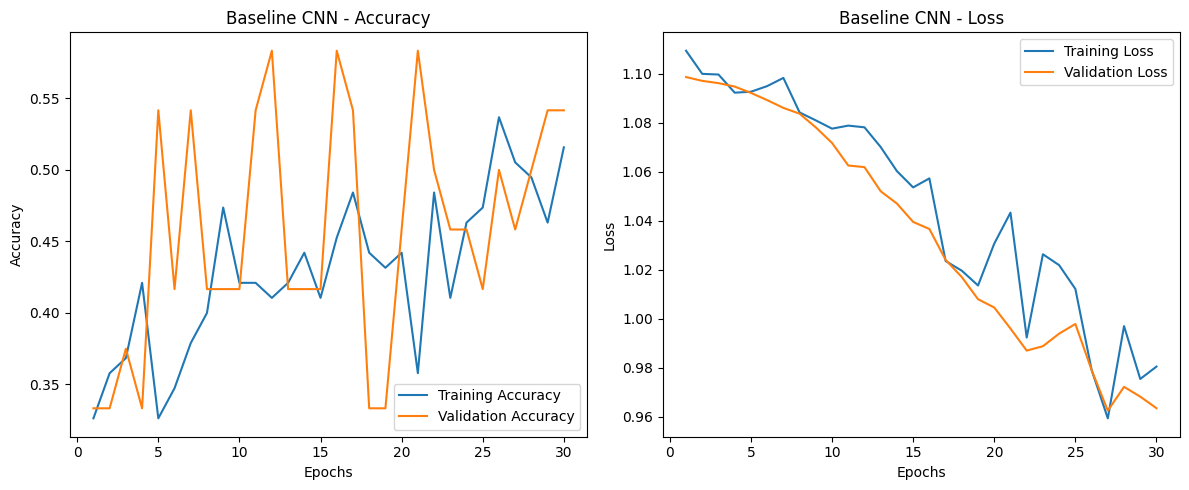

Best validation accuracy: 0.5833
Best validation loss: 0.9624
Epoch with lowest validation loss: 27


In [50]:
# Extract training history

train_accuracy = history_baseline.history["accuracy"]
val_accuracy = history_baseline.history["val_accuracy"]

train_loss = history_baseline.history["loss"]
val_loss = history_baseline.history["val_loss"]

epochs_range = range(1, len(train_accuracy) + 1)

# Plot accuracy

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(epochs_range, train_accuracy, label="Training Accuracy")
plt.plot(epochs_range, val_accuracy, label="Validation Accuracy")

plt.title("Baseline CNN - Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

# Plot loss

plt.subplot(1, 2, 2)

plt.plot(epochs_range, train_loss, label="Training Loss")
plt.plot(epochs_range, val_loss, label="Validation Loss")

plt.title("Baseline CNN - Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

# Best recorded validation results

print(
    "Best validation accuracy:",
    round(max(val_accuracy), 4)
)

print(
    "Best validation loss:",
    round(min(val_loss), 4)
)

print(
    "Epoch with lowest validation loss:",
    np.argmin(val_loss) + 1
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 303ms/step
Validation Accuracy: 0.4583333333333333

Classification Report:

                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.31      0.50      0.38         8
           Brown Spot       0.60      0.75      0.67         8
            Leaf Smut       1.00      0.12      0.22         8

             accuracy                           0.46        24
            macro avg       0.64      0.46      0.42        24
         weighted avg       0.64      0.46      0.42        24



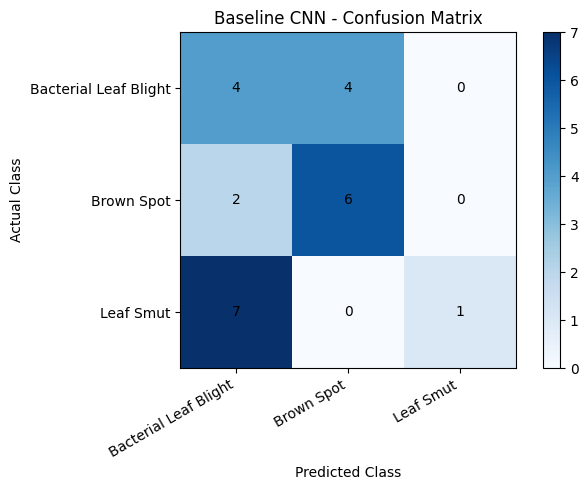

In [51]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Predict validation images

y_pred_prob = cnn_model.predict(X_val)

# Convert probabilities into predicted class labels

y_pred = np.argmax(y_pred_prob, axis=1)

# Calculate accuracy

print(
    "Validation Accuracy:",
    accuracy_score(y_val, y_pred)
)

# Detailed classification report

print("\nClassification Report:\n")

print(
    classification_report(
        y_val,
        y_pred,
        labels=[0, 1, 2],
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

# Confusion matrix

cm = confusion_matrix(
    y_val,
    y_pred,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 5))

plt.imshow(cm, cmap="Blues")

plt.title("Baseline CNN - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    [0, 1, 2],
    label_encoder.classes_,
    rotation=30,
    ha="right"
)

plt.yticks(
    [0, 1, 2],
    label_encoder.classes_
)

for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()

In [52]:
print("Confusion Matrix:")
print(cm)

print("\nClass order:")
for index, class_name in enumerate(label_encoder.classes_):
    print(index, "=", class_name)

Confusion Matrix:
[[4 4 0]
 [2 6 0]
 [7 0 1]]

Class order:
0 = Bacterial Leaf Blight
1 = Brown Spot
2 = Leaf Smut


In [53]:
# Create a fresh augmented CNN

augmented_cnn = build_augmented_cnn()

# Compile the model

augmented_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Create fresh callbacks for this experiment

early_stopping_aug = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_aug = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001,
    verbose=1
)

# Train the augmented CNN

history_augmented = augmented_cnn.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=8,
    callbacks=[
        early_stopping_aug,
        reduce_lr_aug
    ],
    verbose=1
)

Epoch 1/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 190ms/step - accuracy: 0.3579 - loss: 1.1149 - val_accuracy: 0.3333 - val_loss: 1.1009 - learning_rate: 0.0010
Epoch 2/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - accuracy: 0.2737 - loss: 1.1005 - val_accuracy: 0.3333 - val_loss: 1.0993 - learning_rate: 0.0010
Epoch 3/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 97ms/step - accuracy: 0.2737 - loss: 1.1010 - val_accuracy: 0.3333 - val_loss: 1.0988 - learning_rate: 0.0010
Epoch 4/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 111ms/step - accuracy: 0.2842 - loss: 1.1026 - val_accuracy: 0.3333 - val_loss: 1.0983 - learning_rate: 0.0010
Epoch 5/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 99ms/step - accuracy: 0.3158 - loss: 1.1024 - val_accuracy: 0.3750 - val_loss: 1.0979 - learning_rate: 0.0010
Epoch 6/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 126ms/step - accuracy: 0.3579 - loss: 1.0965 - val_accuracy: 0.3750 - val_loss: 1.0981 - learning_rate: 0.0010
Epoch 7/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 168ms/step - accuracy: 0.3579 - loss: 1.0962 - val

In [54]:
# Get best metrics from training history

print(
    "Best validation accuracy:",
    round(max(history_augmented.history["val_accuracy"]), 4)
)

print(
    "Best validation loss:",
    round(min(history_augmented.history["val_loss"]), 4)
)

print(
    "Epoch with highest validation accuracy:",
    np.argmax(history_augmented.history["val_accuracy"]) + 1
)

print(
    "Epoch with lowest validation loss:",
    np.argmin(history_augmented.history["val_loss"]) + 1
)

# Predict using restored model weights

augmented_predictions = augmented_cnn.predict(X_val)

y_pred_augmented = np.argmax(
    augmented_predictions,
    axis=1
)

# Evaluate classification performance

print("\nClassification Report:\n")

print(
    classification_report(
        y_val,
        y_pred_augmented,
        labels=[0, 1, 2],
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

# Confusion matrix

cm_augmented = confusion_matrix(
    y_val,
    y_pred_augmented,
    labels=[0, 1, 2]
)

print("\nConfusion Matrix:")
print(cm_augmented)

Best validation accuracy: 0.5
Best validation loss: 1.0022
Epoch with highest validation accuracy: 18
Epoch with lowest validation loss: 30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step

Classification Report:

                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.40      0.75      0.52         8
           Brown Spot       0.75      0.38      0.50         8
            Leaf Smut       0.20      0.12      0.15         8

             accuracy                           0.42        24
            macro avg       0.45      0.42      0.39        24
         weighted avg       0.45      0.42      0.39        24


Confusion Matrix:
[[6 1 1]
 [2 3 3]
 [7 0 1]]


In [55]:
from sklearn.metrics import accuracy_score, f1_score
import gc

def build_augmented_cnn():

    augmentation = tf.keras.Sequential([

        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1)

    ])

    model = models.Sequential([

        layers.Input(shape=(224, 224, 3)),

        augmentation,

        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.GlobalAveragePooling2D(),

        layers.Dense(64, activation="relu"),
        layers.Dropout(0.5),

        layers.Dense(3, activation="softmax")

    ])

    return model


def run_cross_validation(model_type):

    results = []

    all_true = np.zeros(len(y), dtype=int)
    all_pred = np.zeros(len(y), dtype=int)

    for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):

        print(f"\nStarting Fold {fold_number} — {model_type}")

        tf.keras.backend.clear_session()
        gc.collect()

        # Use the same initialization seed for both model types
        tf.keras.utils.set_random_seed(42 + fold_number)

        X_train_fold = sample_images.numpy()[train_idx]
        X_val_fold = sample_images.numpy()[val_idx]

        y_train_fold = y[train_idx]
        y_val_fold = y[val_idx]

        # Build a fresh model
        if model_type == "Baseline":
            model = build_cnn()
        else:
            model = build_augmented_cnn()

        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )

        # Fresh callbacks for each fold
        callbacks = [

            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=5,
                restore_best_weights=True
            ),

            tf.keras.callbacks.ReduceLROnPlateau(
                monitor="val_loss",
                factor=0.5,
                patience=3,
                min_lr=0.00001
            )

        ]

        history = model.fit(
            X_train_fold,
            y_train_fold,
            validation_data=(X_val_fold, y_val_fold),
            epochs=30,
            batch_size=8,
            callbacks=callbacks,
            verbose=0
        )

        # Evaluate the restored best model
        predictions = model.predict(X_val_fold, verbose=0)
        predicted_classes = np.argmax(predictions, axis=1)

        accuracy = accuracy_score(
            y_val_fold,
            predicted_classes
        )

        macro_f1 = f1_score(
            y_val_fold,
            predicted_classes,
            average="macro",
            zero_division=0
        )

        all_true[val_idx] = y_val_fold
        all_pred[val_idx] = predicted_classes

        results.append({

            "Fold": fold_number,
            "Accuracy": accuracy,
            "Macro_F1": macro_f1,
            "Best_Val_Loss": min(history.history["val_loss"]),
            "Epochs": len(history.history["loss"])

        })

        print("Accuracy:", round(accuracy, 4))
        print("Macro F1:", round(macro_f1, 4))
        print("Epochs:", len(history.history["loss"]))

        del model, history
        del X_train_fold, X_val_fold

        gc.collect()

    return pd.DataFrame(results), all_true, all_pred


print("Five-fold cross-validation experiment is ready!")

Five-fold cross-validation experiment is ready!


In [56]:
IMG_HEIGHT = 128
IMG_WIDTH = 448

def preprocess_image_rectangular(image_path):
    image = tf.io.read_file(image_path)

    image = tf.io.decode_jpeg(
        image,
        channels=3
    )

    image = tf.image.resize_with_pad(
        image,
        target_height=IMG_HEIGHT,
        target_width=IMG_WIDTH
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image


# Test preprocessing on one image

test_image = preprocess_image_rectangular(X[0])

print("Image shape:", test_image.shape)
print("Data type:", test_image.dtype)
print("Minimum pixel value:", tf.reduce_min(test_image).numpy())
print("Maximum pixel value:", tf.reduce_max(test_image).numpy())

Image shape: (128, 448, 3)
Data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 0.9386221


In [57]:
# Preprocess all images using rectangular dimensions

rectangular_images = []

for image_path in X:
    image = preprocess_image_rectangular(image_path)
    rectangular_images.append(image)

# Stack individual images into one tensor
rectangular_images = tf.stack(rectangular_images)

# Verify the dataset
print("Dataset shape:", rectangular_images.shape)
print("Data type:", rectangular_images.dtype)

print(
    "All values finite:",
    tf.reduce_all(
        tf.math.is_finite(rectangular_images)
    ).numpy()
)

print(
    "Pixel range:",
    tf.reduce_min(rectangular_images).numpy(),
    "to",
    tf.reduce_max(rectangular_images).numpy()
)

Dataset shape: (119, 128, 448, 3)
Data type: <dtype: 'float32'>
All values finite: True
Pixel range: 0.0 to 1.0


In [58]:
from tensorflow.keras import layers, models

def build_rectangular_cnn(use_augmentation=False):

    model_layers = [
        layers.Input(shape=(128, 448, 3))
    ]

    # Apply augmentation only when requested
    if use_augmentation:
        model_layers.append(
            layers.RandomFlip("horizontal")
        )
        model_layers.append(
            layers.RandomRotation(0.1)
        )
        model_layers.append(
            layers.RandomZoom(0.1)
        )

    # CNN feature extraction
    model_layers.extend([
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.GlobalAveragePooling2D(),

        layers.Dense(64, activation="relu"),
        layers.Dropout(0.5),

        layers.Dense(3, activation="softmax")
    ])

    model = models.Sequential(model_layers)

    return model


# Build both models
rect_baseline = build_rectangular_cnn(
    use_augmentation=False
)

rect_augmented = build_rectangular_cnn(
    use_augmentation=True
)

print("BASELINE CNN")
rect_baseline.summary()

print("\nAUGMENTED CNN")
rect_augmented.summary()

BASELINE CNN


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)                    │ (None, 126, 446, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_8 (MaxPooling2D)       │ (None, 63, 223, 32)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_9 (Conv2D)                    │ (None, 61, 221, 64)         │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_9 (MaxPooling2D)       │ (None, 30, 110, 64)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_3           │ (None, 64)                  │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 3)                   │             195 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,747 (92.76 KB)

 Trainable params: 23,747 (92.76 KB)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)           │ (None, 128, 448, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_rotation_1 (RandomRotation)   │ (None, 128, 448, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_zoom_1 (RandomZoom)           │ (None, 128, 448, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_10 (Conv2D)                   │ (None, 126, 446, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_10 (MaxPooling2D)      │ (None, 63, 223, 32)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_11 (Conv2D)                   │ (None, 61, 221, 64)         │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_11 (MaxPooling2D)      │ (None, 30, 110, 64)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_4           │ (None, 64)                  │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 3)                   │             195 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,747 (92.76 KB)

 Trainable params: 23,747 (92.76 KB)

 Non-trainable params: 0 (0.00 B)

In [59]:
# Prepare image and label arrays

X_rect = rectangular_images.numpy()
y_rect = y.copy()

# Verify that the original folds match our new dataset
print("Number of images:", len(X_rect))
print("Number of labels:", len(y_rect))
print("Number of folds:", len(folds))

# Verify every image appears in validation exactly once
validation_counts_rect = np.zeros(
    len(X_rect),
    dtype=int
)

for train_idx, val_idx in folds:
    validation_counts_rect[val_idx] += 1

print(
    "Every image validated exactly once:",
    np.all(validation_counts_rect == 1)
)

# Check fold sizes
for fold_number, (train_idx, val_idx) in enumerate(
    folds,
    start=1
):
    print(
        f"Fold {fold_number}: "
        f"Train = {len(train_idx)}, "
        f"Validation = {len(val_idx)}"
    )

Number of images: 119
Number of labels: 119
Number of folds: 5
Every image validated exactly once: True
Fold 1: Train = 95, Validation = 24
Fold 2: Train = 95, Validation = 24
Fold 3: Train = 95, Validation = 24
Fold 4: Train = 95, Validation = 24
Fold 5: Train = 96, Validation = 23


In [60]:
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

def run_cross_validation(use_augmentation):

    experiment_name = (
        "Augmented CNN" if use_augmentation
        else "Baseline CNN"
    )

    print(f"\n{'='*55}")
    print(f"STARTING: {experiment_name}")
    print(f"{'='*55}")

    results = []
    oof_predictions = np.full(len(y_rect), -1)

    for fold_number, (train_idx, val_idx) in enumerate(
        folds,
        start=1
    ):

        print(f"\nTraining Fold {fold_number}/5...")

        # Reset model state and random seed
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(42 + fold_number)

        # Separate training and validation data
        X_train = X_rect[train_idx]
        X_val = X_rect[val_idx]

        y_train = y_rect[train_idx]
        y_val = y_rect[val_idx]

        # Build a fresh model
        model = build_rectangular_cnn(
            use_augmentation=use_augmentation
        )

        model.compile(
            optimizer=tf.keras.optimizers.Adam(
                learning_rate=0.001
            ),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )

        # Fresh callbacks for this fold
        early_stopping = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
            verbose=0
        )

        reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=0.00001,
            verbose=0
        )

        # Train
        history = model.fit(
            X_train,
            y_train,
            validation_data=(X_val, y_val),
            epochs=30,
            batch_size=8,
            callbacks=[early_stopping, reduce_lr],
            verbose=0
        )

        # Predict on the validation fold
        probabilities = model.predict(
            X_val,
            verbose=0
        )

        predictions = np.argmax(
            probabilities,
            axis=1
        )

        # Store out-of-fold predictions
        oof_predictions[val_idx] = predictions

        # Calculate evaluation metrics
        accuracy = accuracy_score(
            y_val,
            predictions
        )

        macro_f1 = f1_score(
            y_val,
            predictions,
            average="macro",
            zero_division=0
        )

        best_val_loss = min(
            history.history["val_loss"]
        )

        results.append({
            "Fold": fold_number,
            "Accuracy": accuracy,
            "Macro_F1": macro_f1,
            "Best_Val_Loss": best_val_loss,
            "Epochs_Trained": len(
                history.history["loss"]
            )
        })

        print(
            f"Fold {fold_number} | "
            f"Accuracy: {accuracy:.4f} | "
            f"Macro F1: {macro_f1:.4f} | "
            f"Best Val Loss: {best_val_loss:.4f} | "
            f"Epochs: {len(history.history['loss'])}"
        )

    results_df = pd.DataFrame(results)

    print(f"\n{experiment_name} — Fold Results")
    print(results_df.round(4).to_string(index=False))

    print("\nAverage Cross-Validation Results:")
    print(
        results_df[
            ["Accuracy", "Macro_F1", "Best_Val_Loss"]
        ].mean().round(4)
    )

    print("\nOut-of-Fold Classification Report:")
    print(
        classification_report(
            y_rect,
            oof_predictions,
            labels=[0, 1, 2],
            target_names=label_encoder.classes_,
            zero_division=0
        )
    )

    print("Out-of-Fold Confusion Matrix:")
    print(
        confusion_matrix(
            y_rect,
            oof_predictions,
            labels=[0, 1, 2]
        )
    )

    return results_df, oof_predictions


# Experiment 1: Baseline CNN
baseline_cv_results, baseline_oof = run_cross_validation(
    use_augmentation=False
)

# Experiment 2: Augmented CNN
augmented_cv_results, augmented_oof = run_cross_validation(
    use_augmentation=True
)


STARTING: Baseline CNN

Training Fold 1/5...

Fold 1 | Accuracy: 0.4167 | Macro F1: 0.3872 | Best Val Loss: 0.8313 | Epochs: 30

Training Fold 2/5...
Fold 2 | Accuracy: 0.6667 | Macro F1: 0.6631 | Best Val Loss: 0.8016 | Epochs: 30

Training Fold 3/5...
Fold 3 | Accuracy: 0.6250 | Macro F1: 0.6042 | Best Val Loss: 0.8028 | Epochs: 30

Training Fold 4/5...
Fold 4 | Accuracy: 0.7083 | Macro F1: 0.7028 | Best Val Loss: 0.8475 | Epochs: 30

Training Fold 5/5...
Fold 5 | Accuracy: 0.6522 | Macro F1: 0.6412 | Best Val Loss: 0.8782 | Epochs: 30

Baseline CNN — Fold Results
 Fold  Accuracy  Macro_F1  Best_Val_Loss  Epochs_Trained
    1    0.4167    0.3872         0.8313              30
    2    0.6667    0.6631         0.8016              30
    3    0.6250    0.6042         0.8028              30
    4    0.7083    0.7028         0.8475              30
    5    0.6522    0.6412         0.8782              30

Average Cross-Validation Results:
Accuracy         0.6138
Macro_F1         0.5997
B

In [61]:
from tensorflow.keras.applications import MobileNetV2

# Load pretrained MobileNetV2
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(128, 448, 3)
)

# Freeze pretrained layers
base_model.trainable = False

# Build complete classification model
inputs = layers.Input(shape=(128, 448, 3))

# Convert pixels from [0, 1] to [-1, 1]
x = layers.Rescaling(
    scale=2.0,
    offset=-1.0
)(inputs)

# Extract pretrained image features
x = base_model(
    x,
    training=False
)

# Classification head
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    3,
    activation="softmax"
)(x)

transfer_model = models.Model(
    inputs,
    outputs
)

# Compile
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

transfer_model.summary()

C:\Users\Pavan\AppData\Local\Temp\ipykernel_112284\1762017345.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)           │ (None, 128, 448, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 128, 448, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 4, 14, 1280)         │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 3)                   │           3,843 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [62]:
# Prepare Fold 1 data

train_idx, val_idx = folds[0]

X_train = X_rect[train_idx]
X_val = X_rect[val_idx]

y_train = y_rect[train_idx]
y_val = y_rect[val_idx]

# Train the model
history_transfer = transfer_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=8,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=6,
            restore_best_weights=True,
            verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=0.00001,
            verbose=1
        )
    ],
    verbose=1
)

Epoch 1/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 13s 669ms/step - accuracy: 0.4842 - loss: 1.0634 - val_accuracy: 0.5000 - val_loss: 0.8577 - learning_rate: 0.0010
Epoch 2/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 154ms/step - accuracy: 0.7684 - loss: 0.6090 - val_accuracy: 0.7917 - val_loss: 0.5621 - learning_rate: 0.0010
Epoch 3/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 153ms/step - accuracy: 0.8737 - loss: 0.3837 - val_accuracy: 1.0000 - val_loss: 0.3985 - learning_rate: 0.0010
Epoch 4/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 155ms/step - accuracy: 0.9368 - loss: 0.2963 - val_accuracy: 1.0000 - val_loss: 0.3169 - learning_rate: 0.0010
Epoch 5/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 154ms/step - accuracy: 0.9368 - loss: 0.2350 - val_accuracy: 1.0000 - val_loss: 0.2650 - learning_rate: 0.0010
Epoch 6/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 155ms/step - accuracy: 0.9789 - loss: 0.1906 - val_accuracy: 1.0000 - val_loss: 0.2328 - learning_rate: 0.0010
Epoch 7/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 159ms/step - accuracy: 0.9895 - loss: 0.1607 -

In [63]:
# Best training metrics

print(
    "Best validation accuracy:",
    max(history_transfer.history["val_accuracy"])
)

print(
    "Best validation loss:",
    min(history_transfer.history["val_loss"])
)

# Generate predictions
transfer_probabilities = transfer_model.predict(
    X_val,
    verbose=0
)

transfer_predictions = np.argmax(
    transfer_probabilities,
    axis=1
)

# Classification report
print("\nClassification Report:\n")

print(
    classification_report(
        y_val,
        transfer_predictions,
        labels=[0, 1, 2],
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

# Confusion matrix
transfer_cm = confusion_matrix(
    y_val,
    transfer_predictions,
    labels=[0, 1, 2]
)

print("\nConfusion Matrix:")
print(transfer_cm)

Best validation accuracy: 1.0
Best validation loss: 0.09091535210609436

Classification Report:

                       precision    recall  f1-score   support

Bacterial Leaf Blight       1.00      1.00      1.00         8
           Brown Spot       1.00      1.00      1.00         8
            Leaf Smut       1.00      1.00      1.00         8

             accuracy                           1.00        24
            macro avg       1.00      1.00      1.00        24
         weighted avg       1.00      1.00      1.00        24


Confusion Matrix:
[[8 0 0]
 [0 8 0]
 [0 0 8]]


In [64]:
def build_transfer_model():

    base_model = MobileNetV2(
        weights="imagenet",
        include_top=False,
        input_shape=(128, 448, 3)
    )

    # Freeze pretrained layers
    base_model.trainable = False

    inputs = layers.Input(shape=(128, 448, 3))

    x = layers.Rescaling(
        scale=2.0,
        offset=-1.0
    )(inputs)

    x = base_model(x, training=False)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)

    outputs = layers.Dense(
        3,
        activation="softmax"
    )(x)

    model = models.Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


def run_mobilenet_cv():

    results = []
    oof_predictions = np.full(len(y_rect), -1)

    for fold_number, (train_idx, val_idx) in enumerate(
        folds,
        start=1
    ):

        print(f"\n{'='*45}")
        print(f"MobileNetV2 — Fold {fold_number}/5")
        print(f"{'='*45}")

        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(42 + fold_number)

        X_train = X_rect[train_idx]
        X_val = X_rect[val_idx]

        y_train = y_rect[train_idx]
        y_val = y_rect[val_idx]

        model = build_transfer_model()

        early_stopping = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=6,
            restore_best_weights=True,
            verbose=0
        )

        reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=0.00001,
            verbose=0
        )

        history = model.fit(
            X_train,
            y_train,
            validation_data=(X_val, y_val),
            epochs=30,
            batch_size=8,
            callbacks=[
                early_stopping,
                reduce_lr
            ],
            verbose=0
        )

        probabilities = model.predict(
            X_val,
            verbose=0
        )

        predictions = np.argmax(
            probabilities,
            axis=1
        )

        oof_predictions[val_idx] = predictions

        accuracy = accuracy_score(
            y_val,
            predictions
        )

        macro_f1 = f1_score(
            y_val,
            predictions,
            average="macro",
            zero_division=0
        )

        best_val_loss = min(
            history.history["val_loss"]
        )

        results.append({
            "Fold": fold_number,
            "Accuracy": accuracy,
            "Macro_F1": macro_f1,
            "Best_Val_Loss": best_val_loss,
            "Epochs_Trained": len(history.history["loss"])
        })

        print(
            f"Accuracy: {accuracy:.4f} | "
            f"Macro F1: {macro_f1:.4f} | "
            f"Best Val Loss: {best_val_loss:.4f} | "
            f"Epochs: {len(history.history['loss'])}"
        )

        del model

    results_df = pd.DataFrame(results)

    print("\nMOBILENETV2 FOLD RESULTS")
    print(results_df.round(4).to_string(index=False))

    print("\nAVERAGE CROSS-VALIDATION RESULTS")
    print(
        results_df[
            ["Accuracy", "Macro_F1", "Best_Val_Loss"]
        ].mean().round(4)
    )

    print("\nOUT-OF-FOLD CLASSIFICATION REPORT")
    print(
        classification_report(
            y_rect,
            oof_predictions,
            labels=[0, 1, 2],
            target_names=label_encoder.classes_,
            zero_division=0
        )
    )

    print("\nOUT-OF-FOLD CONFUSION MATRIX")
    print(
        confusion_matrix(
            y_rect,
            oof_predictions,
            labels=[0, 1, 2]
        )
    )

    return results_df, oof_predictions


# Run the complete experiment
mobilenet_cv_results, mobilenet_oof = run_mobilenet_cv()


MobileNetV2 — Fold 1/5


C:\Users\Pavan\AppData\Local\Temp\ipykernel_112284\2463802746.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


Accuracy: 0.9583 | Macro F1: 0.9582 | Best Val Loss: 0.1331 | Epochs: 30

MobileNetV2 — Fold 2/5


C:\Users\Pavan\AppData\Local\Temp\ipykernel_112284\2463802746.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


Accuracy: 0.9583 | Macro F1: 0.9582 | Best Val Loss: 0.2173 | Epochs: 30

MobileNetV2 — Fold 3/5


C:\Users\Pavan\AppData\Local\Temp\ipykernel_112284\2463802746.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


Accuracy: 0.9583 | Macro F1: 0.9582 | Best Val Loss: 0.1158 | Epochs: 30

MobileNetV2 — Fold 4/5


C:\Users\Pavan\AppData\Local\Temp\ipykernel_112284\2463802746.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


Accuracy: 0.9167 | Macro F1: 0.9165 | Best Val Loss: 0.3019 | Epochs: 20

MobileNetV2 — Fold 5/5


C:\Users\Pavan\AppData\Local\Temp\ipykernel_112284\2463802746.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


Accuracy: 0.7826 | Macro F1: 0.7725 | Best Val Loss: 0.4537 | Epochs: 30

MOBILENETV2 FOLD RESULTS
 Fold  Accuracy  Macro_F1  Best_Val_Loss  Epochs_Trained
    1    0.9583    0.9582         0.1331              30
    2    0.9583    0.9582         0.2173              30
    3    0.9583    0.9582         0.1158              30
    4    0.9167    0.9165         0.3019              20
    5    0.7826    0.7725         0.4537              30

AVERAGE CROSS-VALIDATION RESULTS
Accuracy         0.9149
Macro_F1         0.9127
Best_Val_Loss    0.2443
dtype: float64

OUT-OF-FOLD CLASSIFICATION REPORT
                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.95      0.95      0.95        40
           Brown Spot       0.90      0.88      0.89        40
            Leaf Smut       0.90      0.92      0.91        39

             accuracy                           0.92       119
            macro avg       0.92      0.92      0.92       119
         weighted avg  

In [65]:

def build_transfer_model():

    IMG_HEIGHT = 224
    IMG_WIDTH = 224

    base_model = MobileNetV2(
        weights="imagenet",
        include_top=False,
        input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)
    )

    # Freeze pretrained layers
    base_model.trainable = False

    inputs = layers.Input(
        shape=(IMG_HEIGHT, IMG_WIDTH, 3)
    )

    # MobileNetV2 preprocessing: [0, 255] -> [-1, 1]
    x = layers.Rescaling(
        scale=1.0 / 127.5,
        offset=-1.0
    )(inputs)

    x = base_model(x, training=False)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dropout(0.3)(x)

    outputs = layers.Dense(
        3,
        activation="softmax"
    )(x)

    model = models.Model(
        inputs=inputs,
        outputs=outputs
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


def run_mobilenet_cv():

    results = []

    oof_predictions = np.full(
        len(y_rect),
        -1,
        dtype=int
    )

    for fold_number, (train_idx, val_idx) in enumerate(
        folds,
        start=1
    ):

        print(f"\n{'='*45}")
        print(f"MobileNetV2 — Fold {fold_number}/5")
        print(f"{'='*45}")

        tf.keras.backend.clear_session()

        tf.keras.utils.set_random_seed(
            42 + fold_number
        )

        # Extract fold data
        X_train = X_rect[train_idx]
        X_val = X_rect[val_idx]

        y_train = y_rect[train_idx]
        y_val = y_rect[val_idx]

        # Resize images to MobileNetV2 input dimensions
        X_train_resized = tf.image.resize(
            X_train,
            (224, 224)
        ).numpy()

        X_val_resized = tf.image.resize(
            X_val,
            (224, 224)
        ).numpy()

        # Build model
        model = build_transfer_model()

        # Early stopping
        early_stopping = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=6,
            restore_best_weights=True,
            verbose=0
        )

        # Learning rate reduction
        reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=0.00001,
            verbose=0
        )

        # Train model
        history = model.fit(
            X_train_resized,
            y_train,
            validation_data=(
                X_val_resized,
                y_val
            ),
            epochs=30,
            batch_size=8,
            callbacks=[
                early_stopping,
                reduce_lr
            ],
            verbose=0
        )

        # Predictions
        probabilities = model.predict(
            X_val_resized,
            verbose=0
        )

        predictions = np.argmax(
            probabilities,
            axis=1
        )

        # Store out-of-fold predictions
        oof_predictions[val_idx] = predictions

        # Evaluation
        accuracy = accuracy_score(
            y_val,
            predictions
        )

        macro_f1 = f1_score(
            y_val,
            predictions,
            average="macro",
            zero_division=0
        )

        best_val_loss = min(
            history.history["val_loss"]
        )

        results.append({
            "Fold": fold_number,
            "Accuracy": accuracy,
            "Macro_F1": macro_f1,
            "Best_Val_Loss": best_val_loss,
            "Epochs_Trained": len(
                history.history["loss"]
            )
        })

        print(
            f"Accuracy: {accuracy:.4f} | "
            f"Macro F1: {macro_f1:.4f} | "
            f"Best Val Loss: {best_val_loss:.4f} | "
            f"Epochs: {len(history.history['loss'])}"
        )

        del model

        del X_train_resized
        del X_val_resized

    # Results DataFrame
    results_df = pd.DataFrame(results)

    print("\nMOBILENETV2 FOLD RESULTS")

    print(
        results_df.round(4).to_string(index=False)
    )

    # Average results
    print("\nAVERAGE CROSS-VALIDATION RESULTS")

    print(
        results_df[
            [
                "Accuracy",
                "Macro_F1",
                "Best_Val_Loss"
            ]
        ].mean().round(4)
    )

    # Check OOF predictions
    if np.any(oof_predictions == -1):
        raise ValueError(
            "Some samples do not have OOF predictions."
        )

    # Classification report
    print("\nOUT-OF-FOLD CLASSIFICATION REPORT")

    print(
        classification_report(
            y_rect,
            oof_predictions,
            labels=[0, 1, 2],
            target_names=label_encoder.classes_,
            zero_division=0
        )
    )

    # Confusion matrix
    print("\nOUT-OF-FOLD CONFUSION MATRIX")

    print(
        confusion_matrix(
            y_rect,
            oof_predictions,
            labels=[0, 1, 2]
        )
    )

    return results_df, oof_predictions


# Run complete experiment
mobilenet_cv_results, mobilenet_oof = run_mobilenet_cv()



MobileNetV2 — Fold 1/5
Accuracy: 0.3333 | Macro F1: 0.2395 | Best Val Loss: 1.0774 | Epochs: 30

MobileNetV2 — Fold 2/5
Accuracy: 0.4167 | Macro F1: 0.4167 | Best Val Loss: 1.0534 | Epochs: 30

MobileNetV2 — Fold 3/5
Accuracy: 0.3333 | Macro F1: 0.3359 | Best Val Loss: 1.0686 | Epochs: 30

MobileNetV2 — Fold 4/5
Accuracy: 0.4583 | Macro F1: 0.4140 | Best Val Loss: 1.0533 | Epochs: 30

MobileNetV2 — Fold 5/5
Accuracy: 0.4783 | Macro F1: 0.4697 | Best Val Loss: 1.0660 | Epochs: 30

MOBILENETV2 FOLD RESULTS
 Fold  Accuracy  Macro_F1  Best_Val_Loss  Epochs_Trained
    1    0.3333    0.2395         1.0774              30
    2    0.4167    0.4167         1.0534              30
    3    0.3333    0.3359         1.0686              30
    4    0.4583    0.4140         1.0533              30
    5    0.4783    0.4697         1.0660              30

AVERAGE CROSS-VALIDATION RESULTS
Accuracy         0.4040
Macro_F1         0.3752
Best_Val_Loss    1.0637
dtype: float64

OUT-OF-FOLD CLASSIFICATIO

In [66]:
# Load a fresh frozen MobileNetV2 feature extractor

feature_backbone = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(128, 448, 3)
)

feature_backbone.trainable = False

# Build feature extraction model

feature_input = layers.Input(
    shape=(128, 448, 3)
)

x = layers.Rescaling(
    scale=2.0,
    offset=-1.0
)(feature_input)

x = feature_backbone(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

feature_extractor = models.Model(
    feature_input,
    x
)

# Extract features from all images

mobilenet_features = feature_extractor.predict(
    X_rect,
    batch_size=8,
    verbose=1
)

print("Feature matrix shape:", mobilenet_features.shape)
print("Data type:", mobilenet_features.dtype)
print(
    "All values finite:",
    np.isfinite(mobilenet_features).all()
)

C:\Users\Pavan\AppData\Local\Temp\ipykernel_112284\2298759314.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  feature_backbone = MobileNetV2(


15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 207ms/step
Feature matrix shape: (119, 1280)
Data type: float32
All values finite: True


### SVM

In [67]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

svm_models = {
    "Linear SVM": SVC(kernel="linear", C=1.0),
    "RBF SVM": SVC(kernel="rbf", C=1.0, gamma="scale")
}

svm_results = {}

for model_name, classifier in svm_models.items():

    print("\n" + "=" * 55)
    print(model_name)
    print("=" * 55)

    fold_accuracies = []
    fold_f1_scores = []
    oof_predictions = np.zeros(len(y_rect), dtype=int)

    for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):

        X_train = mobilenet_features[train_idx]
        X_val = mobilenet_features[val_idx]

        y_train = y_rect[train_idx]
        y_val = y_rect[val_idx]

        pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("svm", classifier)
        ])

        pipeline.fit(X_train, y_train)

        predictions = pipeline.predict(X_val)

        accuracy = accuracy_score(y_val, predictions)
        macro_f1 = f1_score(
            y_val,
            predictions,
            average="macro"
        )

        fold_accuracies.append(accuracy)
        fold_f1_scores.append(macro_f1)

        oof_predictions[val_idx] = predictions

        print(
            f"Fold {fold_number}: "
            f"Accuracy = {accuracy:.4f}, "
            f"Macro F1 = {macro_f1:.4f}"
        )

    print("\nOverall Cross-Validation Results")
    print("Mean Accuracy:", round(np.mean(fold_accuracies), 4))
    print("Mean Macro F1:", round(np.mean(fold_f1_scores), 4))

    print("\nOut-of-Fold Classification Report:")
    print(
        classification_report(
            y_rect,
            oof_predictions,
            target_names=label_encoder.classes_,
            zero_division=0
        )
    )

    print("Out-of-Fold Confusion Matrix:")
    print(confusion_matrix(y_rect, oof_predictions))

    svm_results[model_name] = {
        "fold_accuracies": fold_accuracies,
        "fold_f1_scores": fold_f1_scores,
        "mean_accuracy": np.mean(fold_accuracies),
        "mean_macro_f1": np.mean(fold_f1_scores),
        "oof_predictions": oof_predictions
    }


Linear SVM
Fold 1: Accuracy = 0.9583, Macro F1 = 0.9582
Fold 2: Accuracy = 0.9583, Macro F1 = 0.9582
Fold 3: Accuracy = 1.0000, Macro F1 = 1.0000
Fold 4: Accuracy = 0.9167, Macro F1 = 0.9165
Fold 5: Accuracy = 0.7391, Macro F1 = 0.7215

Overall Cross-Validation Results
Mean Accuracy: 0.9145
Mean Macro F1: 0.9109

Out-of-Fold Classification Report:
                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.88      0.95      0.92        40
           Brown Spot       0.94      0.82      0.88        40
            Leaf Smut       0.93      0.97      0.95        39

             accuracy                           0.92       119
            macro avg       0.92      0.92      0.92       119
         weighted avg       0.92      0.92      0.91       119

Out-of-Fold Confusion Matrix:
[[38  2  0]
 [ 4 33  3]
 [ 1  0 38]]

RBF SVM
Fold 1: Accuracy = 0.8750, Macro F1 = 0.8775
Fold 2: Accuracy = 0.7083, Macro F1 = 0.7073
Fold 3: Accuracy = 0.7500, Macro F1 = 0

In [68]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import numpy as np

# Values of C to investigate
param_grid = {
    "svm__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

# Store predictions and results
linear_svm_oof = np.zeros(len(y_rect), dtype=int)
nested_svm_results = []
selected_c_values = []

for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):

    X_train = mobilenet_features[train_idx]
    X_val = mobilenet_features[val_idx]

    y_train = y_rect[train_idx]
    y_val = y_rect[val_idx]

    # Scaling and SVM are kept together in a pipeline
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="linear"))
    ])

    # Inner cross-validation for hyperparameter selection
    inner_cv = StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    )

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="f1_macro",
        cv=inner_cv,
        n_jobs=-1
    )

    # Tune only on the outer training data
    grid_search.fit(X_train, y_train)

    # Evaluate on the untouched outer validation fold
    best_model = grid_search.best_estimator_
    predictions = best_model.predict(X_val)

    linear_svm_oof[val_idx] = predictions

    accuracy = accuracy_score(y_val, predictions)
    macro_f1 = f1_score(y_val, predictions, average="macro")

    selected_c_values.append(grid_search.best_params_["svm__C"])

    nested_svm_results.append({
        "Fold": fold_number,
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Best C": grid_search.best_params_["svm__C"]
    })

    print(f"\nFold {fold_number}")
    print("Best C:", grid_search.best_params_["svm__C"])
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")

# Overall nested cross-validation results
nested_svm_df = pd.DataFrame(nested_svm_results)

print("\n" + "=" * 55)
print("NESTED LINEAR SVM RESULTS")
print("=" * 55)

print(nested_svm_df.to_string(index=False))

print("\nMean Accuracy:",
      round(nested_svm_df["Accuracy"].mean(), 4))

print("Mean Macro F1:",
      round(nested_svm_df["Macro F1"].mean(), 4))

print("\nSelected C values:", selected_c_values)

print("\nOut-of-Fold Classification Report:")
print(classification_report(
    y_rect,
    linear_svm_oof,
    target_names=label_encoder.classes_
))

print("Out-of-Fold Confusion Matrix:")
print(confusion_matrix(y_rect, linear_svm_oof))


Fold 1
Best C: 0.01
Accuracy: 0.9583
Macro F1: 0.9582

Fold 2
Best C: 0.01
Accuracy: 0.9583
Macro F1: 0.9582

Fold 3
Best C: 0.01
Accuracy: 1.0000
Macro F1: 1.0000

Fold 4
Best C: 0.01
Accuracy: 0.9167
Macro F1: 0.9165

Fold 5
Best C: 0.001
Accuracy: 0.7826
Macro F1: 0.7696

NESTED LINEAR SVM RESULTS
 Fold  Accuracy  Macro F1  Best C
    1  0.958333  0.958170   0.010
    2  0.958333  0.958170   0.010
    3  1.000000  1.000000   0.010
    4  0.916667  0.916503   0.010
    5  0.782609  0.769591   0.001

Mean Accuracy: 0.9232
Mean Macro F1: 0.9205

Selected C values: [0.01, 0.01, 0.01, 0.01, 0.001]

Out-of-Fold Classification Report:
                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.93      0.95      0.94        40
           Brown Spot       0.94      0.85      0.89        40
            Leaf Smut       0.90      0.97      0.94        39

             accuracy                           0.92       119
            macro avg       0.93      0.92 

In [69]:
# Get the validation indices for Fold 5
fold5_train_idx, fold5_val_idx = folds[4]

# Get the actual and predicted labels for Fold 5
fold5_actual = y_rect[fold5_val_idx]
fold5_predicted = linear_svm_oof[fold5_val_idx]

# Identify incorrectly classified images
wrong_positions = np.where(fold5_actual != fold5_predicted)[0]
wrong_indices = fold5_val_idx[wrong_positions]

print("FOLD 5 ERROR ANALYSIS")
print("=" * 65)

print("Validation images:", len(fold5_val_idx))
print("Correct predictions:", len(fold5_val_idx) - len(wrong_indices))
print("Incorrect predictions:", len(wrong_indices))

# Create a detailed table of misclassified images
error_rows = []

for idx in wrong_indices:
    row = dataset_df.iloc[idx]

    error_rows.append({
        "Filename": row["Filename"],
        "Actual Class": label_encoder.inverse_transform([y_rect[idx]])[0],
        "Predicted Class": label_encoder.inverse_transform(
            [linear_svm_oof[idx]]
        )[0],
        "Width": row["Width"],
        "Height": row["Height"],
        "Aspect Ratio": round(row["Aspect_Ratio"], 2),
        "File Size (KB)": round(row["File_Size"] / 1024, 2)
    })

error_df = pd.DataFrame(error_rows)

print("\nMisclassified Images:")
print(error_df.to_string(index=False))

# Compare the metadata of all Fold 5 validation images
fold5_metadata = dataset_df.iloc[fold5_val_idx].copy()

fold5_metadata["Prediction Correct"] = (
    fold5_actual == fold5_predicted
)

print("\n\nFold 5: Correct vs Incorrect Prediction Metadata")
print(
    fold5_metadata.groupby("Prediction Correct")[
        ["Width", "Height", "Aspect_Ratio", "File_Size"]
    ].mean().round(2)
)

print("\nFold 5 Actual Class Distribution:")
print(
    pd.Series(
        label_encoder.inverse_transform(fold5_actual)
    ).value_counts()
)

print("\nFold 5 Predicted Class Distribution:")
print(
    pd.Series(
        label_encoder.inverse_transform(fold5_predicted)
    ).value_counts()
)

FOLD 5 ERROR ANALYSIS
Validation images: 23
Correct predictions: 18
Incorrect predictions: 5


KeyError: 'File_Size'

In [70]:
print("Dataset columns:")
print(dataset_df.columns.tolist())

print("\nFirst five rows:")
print(dataset_df.head())

Dataset columns:
['Filename', 'File_Path', 'Class', 'Width', 'Height', 'Aspect_Ratio', 'File_Size_KB', 'Encoded_Class']

First five rows:
       Filename                                          File_Path  \
0  DSC_0365.JPG  leaf photos\Data\Bacterial leaf blight-2020081...   
1  DSC_0366.jpg  leaf photos\Data\Bacterial leaf blight-2020081...   
2  DSC_0367.JPG  leaf photos\Data\Bacterial leaf blight-2020081...   
3  DSC_0370.jpg  leaf photos\Data\Bacterial leaf blight-2020081...   
4  DSC_0372.JPG  leaf photos\Data\Bacterial leaf blight-2020081...   

                   Class  Width  Height  Aspect_Ratio  File_Size_KB  \
0  Bacterial Leaf Blight   3081     897      3.434783        456.16   
1  Bacterial Leaf Blight   3081     897      3.434783        408.13   
2  Bacterial Leaf Blight   3081     897      3.434783        442.02   
3  Bacterial Leaf Blight   3081     897      3.434783        418.68   
4  Bacterial Leaf Blight   3081     897      3.434783        470.20   

   Encoded_Cla

In [71]:
# Get Fold 5 validation indices
fold5_train_idx, fold5_val_idx = folds[4]

fold5_actual = y_rect[fold5_val_idx]
fold5_predicted = linear_svm_oof[fold5_val_idx]

# Find incorrect predictions
wrong_positions = np.where(fold5_actual != fold5_predicted)[0]
wrong_indices = fold5_val_idx[wrong_positions]

print("FOLD 5 ERROR ANALYSIS")
print("=" * 65)
print("Validation images:", len(fold5_val_idx))
print("Correct predictions:", len(fold5_val_idx) - len(wrong_indices))
print("Incorrect predictions:", len(wrong_indices))

# Build error-analysis table
error_rows = []

for idx in wrong_indices:
    row = dataset_df.iloc[idx]

    error_rows.append({
        "Filename": row["Filename"],
        "Actual Class": row["Class"],
        "Predicted Class": label_encoder.inverse_transform(
            [linear_svm_oof[idx]]
        )[0],
        "Width": row["Width"],
        "Height": row["Height"],
        "Aspect Ratio": round(row["Aspect_Ratio"], 2),
        "File Size (KB)": round(row["File_Size_KB"], 2)
    })

error_df = pd.DataFrame(error_rows)

print("\nMisclassified Images:")
print(error_df.to_string(index=False))

# Compare metadata for correct and incorrect predictions
fold5_metadata = dataset_df.iloc[fold5_val_idx].copy()

fold5_metadata["Prediction Correct"] = (
    fold5_actual == fold5_predicted
)

print("\n\nFold 5: Correct vs Incorrect Prediction Metadata")

print(
    fold5_metadata.groupby("Prediction Correct")[
        ["Width", "Height", "Aspect_Ratio", "File_Size_KB"]
    ].mean().round(2)
)

print("\nFold 5 Actual Class Distribution:")
print(pd.Series(
    label_encoder.inverse_transform(fold5_actual)
).value_counts())

print("\nFold 5 Predicted Class Distribution:")
print(pd.Series(
    label_encoder.inverse_transform(fold5_predicted)
).value_counts())

FOLD 5 ERROR ANALYSIS
Validation images: 23
Correct predictions: 18
Incorrect predictions: 5

Misclassified Images:
    Filename Actual Class       Predicted Class  Width  Height  Aspect Ratio  File Size (KB)
DSC_0106.jpg   Brown Spot             Leaf Smut   1504     323          4.66          125.44
DSC_0121.jpg   Brown Spot             Leaf Smut   1200     900          1.33          141.44
DSC_0292.JPG   Brown Spot Bacterial Leaf Blight   3081     897          3.43          497.53
DSC_0391.jpg   Brown Spot Bacterial Leaf Blight   3081     897          3.43          425.33
DSC_0509.jpg    Leaf Smut Bacterial Leaf Blight   3081     897          3.43          190.03


Fold 5: Correct vs Incorrect Prediction Metadata
                      Width  Height  Aspect_Ratio  File_Size_KB
Prediction Correct                                             
False               2389.40  782.80          3.26        275.95
True                2676.28  779.61          3.41        358.56

Fold 5 Actual Clas

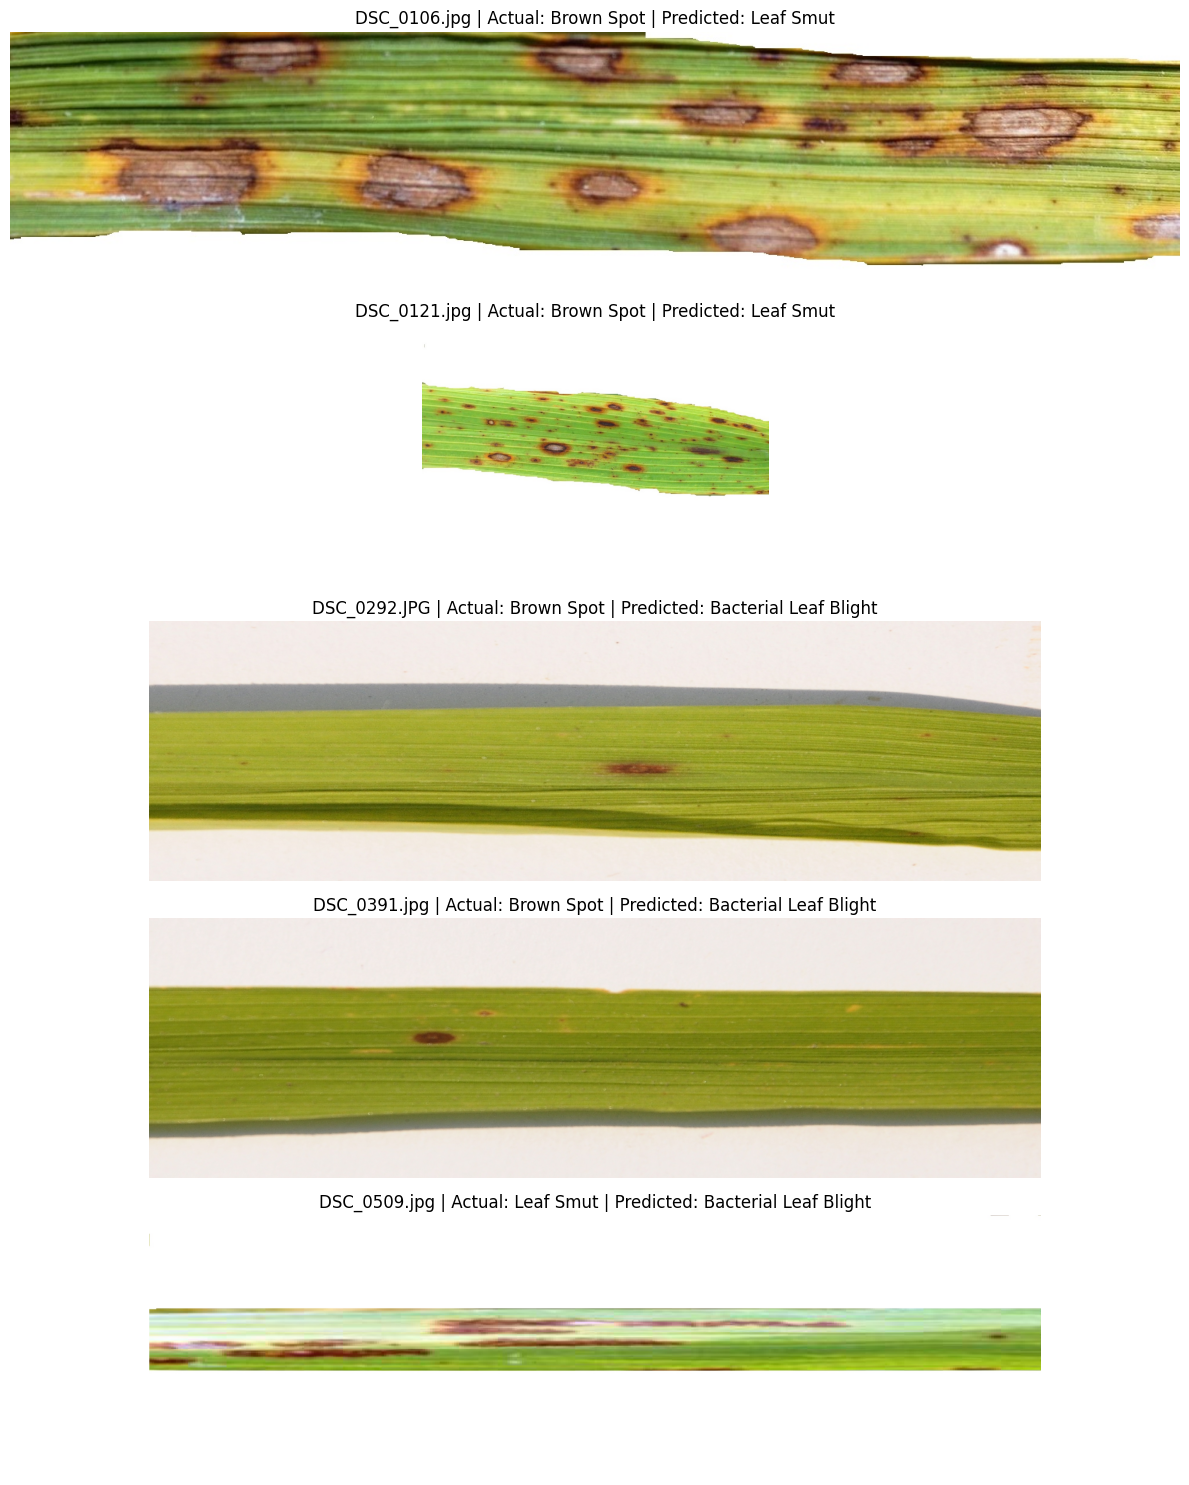

In [72]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(
    nrows=len(wrong_indices),
    ncols=1,
    figsize=(12, 15)
)

for ax, idx in zip(axes, wrong_indices):

    row = dataset_df.iloc[idx]

    image = Image.open(row["File_Path"]).convert("RGB")

    actual = row["Class"]
    predicted = label_encoder.inverse_transform(
        [linear_svm_oof[idx]]
    )[0]

    ax.imshow(image)
    ax.set_title(
        f'{row["Filename"]} | Actual: {actual} | Predicted: {predicted}'
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [73]:
IMG_HEIGHT = 128
IMG_WIDTH = 448

def preprocess_image_direct(image_path):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_jpeg(image, channels=3)

    # Resize directly without preserving the original aspect ratio
    image = tf.image.resize(
        image,
        size=(IMG_HEIGHT, IMG_WIDTH)
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image


# Process all 119 images
direct_images = []

for image_path in X:
    image = preprocess_image_direct(image_path)
    direct_images.append(image)

direct_images = tf.stack(direct_images)

X_direct = direct_images.numpy()

print("Dataset shape:", X_direct.shape)
print("Data type:", X_direct.dtype)
print("Minimum pixel value:", X_direct.min())
print("Maximum pixel value:", X_direct.max())
print("All values finite:", np.isfinite(X_direct).all())

Dataset shape: (119, 128, 448, 3)
Data type: float32
Minimum pixel value: 0.0
Maximum pixel value: 1.0
All values finite: True


In [74]:
# Extract features from directly resized images
direct_features = feature_extractor.predict(
    X_direct,
    batch_size=8,
    verbose=1
)

print("Feature matrix shape:", direct_features.shape)
print("Data type:", direct_features.dtype)
print("All values finite:", np.isfinite(direct_features).all())

15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 180ms/step
Feature matrix shape: (119, 1280)
Data type: float32
All values finite: True


In [75]:
direct_svm_oof = np.zeros(len(y_rect), dtype=int)
direct_svm_results = []
direct_selected_c = []

for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):

    X_train = direct_features[train_idx]
    X_val = direct_features[val_idx]

    y_train = y_rect[train_idx]
    y_val = y_rect[val_idx]

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="linear"))
    ])

    inner_cv = StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    )

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid={
            "svm__C": [0.001, 0.01, 0.1, 1, 10, 100]
        },
        scoring="f1_macro",
        cv=inner_cv,
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)

    best_model = grid_search.best_estimator_
    predictions = best_model.predict(X_val)

    direct_svm_oof[val_idx] = predictions

    accuracy = accuracy_score(y_val, predictions)
    macro_f1 = f1_score(y_val, predictions, average="macro")

    best_c = grid_search.best_params_["svm__C"]

    direct_selected_c.append(best_c)

    direct_svm_results.append({
        "Fold": fold_number,
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Best C": best_c
    })

    print(f"\nFold {fold_number}")
    print("Best C:", best_c)
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")


direct_svm_df = pd.DataFrame(direct_svm_results)

print("\n" + "=" * 55)
print("DIRECT RESIZING — NESTED LINEAR SVM")
print("=" * 55)

print(direct_svm_df.to_string(index=False))

print("\nMean Accuracy:",
      round(direct_svm_df["Accuracy"].mean(), 4))

print("Mean Macro F1:",
      round(direct_svm_df["Macro F1"].mean(), 4))

print("\nSelected C values:", direct_selected_c)

print("\nOut-of-Fold Classification Report:")
print(classification_report(
    y_rect,
    direct_svm_oof,
    target_names=label_encoder.classes_
))

print("Out-of-Fold Confusion Matrix:")
print(confusion_matrix(y_rect, direct_svm_oof))


Fold 1
Best C: 0.001
Accuracy: 0.9583
Macro F1: 0.9582

Fold 2
Best C: 0.01
Accuracy: 0.8333
Macro F1: 0.8356

Fold 3
Best C: 0.001
Accuracy: 1.0000
Macro F1: 1.0000

Fold 4
Best C: 0.001
Accuracy: 0.9167
Macro F1: 0.9165

Fold 5
Best C: 0.01
Accuracy: 0.8261
Macro F1: 0.8265

DIRECT RESIZING — NESTED LINEAR SVM
 Fold  Accuracy  Macro F1  Best C
    1  0.958333  0.958170   0.001
    2  0.833333  0.835621   0.010
    3  1.000000  1.000000   0.001
    4  0.916667  0.916503   0.001
    5  0.826087  0.826489   0.010

Mean Accuracy: 0.9069
Mean Macro F1: 0.9074

Selected C values: [0.001, 0.01, 0.001, 0.001, 0.01]

Out-of-Fold Classification Report:
                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.93      0.95      0.94        40
           Brown Spot       0.89      0.82      0.86        40
            Leaf Smut       0.90      0.95      0.93        39

             accuracy                           0.91       119
            macro avg       0

In [76]:
rbf_svm_oof = np.zeros(len(y_rect), dtype=int)
rbf_svm_results = []
rbf_selected_params = []

rbf_param_grid = {
    "svm__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "svm__gamma": ["scale", 0.0001, 0.001, 0.01, 0.1]
}

for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):

    X_train = mobilenet_features[train_idx]
    X_val = mobilenet_features[val_idx]

    y_train = y_rect[train_idx]
    y_val = y_rect[val_idx]

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf"))
    ])

    inner_cv = StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    )

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=rbf_param_grid,
        scoring="f1_macro",
        cv=inner_cv,
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)

    best_model = grid_search.best_estimator_
    predictions = best_model.predict(X_val)

    rbf_svm_oof[val_idx] = predictions

    accuracy = accuracy_score(y_val, predictions)
    macro_f1 = f1_score(y_val, predictions, average="macro")

    best_params = grid_search.best_params_
    rbf_selected_params.append(best_params)

    rbf_svm_results.append({
        "Fold": fold_number,
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Best C": best_params["svm__C"],
        "Best Gamma": best_params["svm__gamma"]
    })

    print(f"\nFold {fold_number}")
    print("Best parameters:", best_params)
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")


rbf_svm_df = pd.DataFrame(rbf_svm_results)

print("\n" + "=" * 60)
print("NESTED RBF SVM RESULTS")
print("=" * 60)

print(rbf_svm_df.to_string(index=False))

print("\nMean Accuracy:",
      round(rbf_svm_df["Accuracy"].mean(), 4))

print("Mean Macro F1:",
      round(rbf_svm_df["Macro F1"].mean(), 4))

print("\nOut-of-Fold Classification Report:")
print(classification_report(
    y_rect,
    rbf_svm_oof,
    target_names=label_encoder.classes_
))

print("Out-of-Fold Confusion Matrix:")
print(confusion_matrix(y_rect, rbf_svm_oof))


Fold 1
Best parameters: {'svm__C': 100, 'svm__gamma': 0.0001}
Accuracy: 0.9583
Macro F1: 0.9582

Fold 2
Best parameters: {'svm__C': 10, 'svm__gamma': 0.0001}
Accuracy: 0.9167
Macro F1: 0.9167

Fold 3
Best parameters: {'svm__C': 10, 'svm__gamma': 0.0001}
Accuracy: 1.0000
Macro F1: 1.0000

Fold 4
Best parameters: {'svm__C': 10, 'svm__gamma': 0.0001}
Accuracy: 0.9167
Macro F1: 0.9165

Fold 5
Best parameters: {'svm__C': 10, 'svm__gamma': 0.0001}
Accuracy: 0.7826
Macro F1: 0.7746

NESTED RBF SVM RESULTS
 Fold  Accuracy  Macro F1  Best C  Best Gamma
    1  0.958333  0.958170     100      0.0001
    2  0.916667  0.916667      10      0.0001
    3  1.000000  1.000000      10      0.0001
    4  0.916667  0.916503      10      0.0001
    5  0.782609  0.774603      10      0.0001

Mean Accuracy: 0.9149
Mean Macro F1: 0.9132

Out-of-Fold Classification Report:
                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.90      0.95      0.93        40
           

In [77]:
from sklearn.decomposition import PCA

pca_svm_oof = np.zeros(len(y_rect), dtype=int)
pca_svm_results = []

pca_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("svm", SVC(kernel="linear"))
])

pca_param_grid = {
    "pca__n_components": [0.90, 0.95, 0.99],
    "svm__C": [0.001, 0.01, 0.1, 1, 10]
}

for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):

    X_train = mobilenet_features[train_idx]
    X_val = mobilenet_features[val_idx]

    y_train = y_rect[train_idx]
    y_val = y_rect[val_idx]

    inner_cv = StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    )

    grid_search = GridSearchCV(
        estimator=pca_pipeline,
        param_grid=pca_param_grid,
        scoring="f1_macro",
        cv=inner_cv,
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)

    best_model = grid_search.best_estimator_
    predictions = best_model.predict(X_val)

    pca_svm_oof[val_idx] = predictions

    accuracy = accuracy_score(y_val, predictions)
    macro_f1 = f1_score(y_val, predictions, average="macro")

    best_params = grid_search.best_params_

    pca_svm_results.append({
        "Fold": fold_number,
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "PCA Variance": best_params["pca__n_components"],
        "Best C": best_params["svm__C"],
        "Actual Components": best_model.named_steps["pca"].n_components_
    })

    print(f"\nFold {fold_number}")
    print("Best parameters:", best_params)
    print("Actual PCA components:",
          best_model.named_steps["pca"].n_components_)
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")


pca_svm_df = pd.DataFrame(pca_svm_results)

print("\n" + "=" * 60)
print("PCA + LINEAR SVM RESULTS")
print("=" * 60)

print(pca_svm_df.to_string(index=False))

print("\nMean Accuracy:",
      round(pca_svm_df["Accuracy"].mean(), 4))

print("Mean Macro F1:",
      round(pca_svm_df["Macro F1"].mean(), 4))

print("\nOut-of-Fold Classification Report:")
print(classification_report(
    y_rect,
    pca_svm_oof,
    target_names=label_encoder.classes_
))

print("Out-of-Fold Confusion Matrix:")
print(confusion_matrix(y_rect, pca_svm_oof))


Fold 1
Best parameters: {'pca__n_components': 0.95, 'svm__C': 0.01}
Actual PCA components: 65
Accuracy: 0.9583
Macro F1: 0.9582

Fold 2
Best parameters: {'pca__n_components': 0.95, 'svm__C': 0.01}
Actual PCA components: 63
Accuracy: 0.9583
Macro F1: 0.9582

Fold 3
Best parameters: {'pca__n_components': 0.99, 'svm__C': 0.01}
Actual PCA components: 84
Accuracy: 1.0000
Macro F1: 1.0000

Fold 4
Best parameters: {'pca__n_components': 0.99, 'svm__C': 0.01}
Actual PCA components: 84
Accuracy: 0.9167
Macro F1: 0.9165

Fold 5
Best parameters: {'pca__n_components': 0.95, 'svm__C': 0.001}
Actual PCA components: 64
Accuracy: 0.7826
Macro F1: 0.7696

PCA + LINEAR SVM RESULTS
 Fold  Accuracy  Macro F1  PCA Variance  Best C  Actual Components
    1  0.958333  0.958170          0.95   0.010                 65
    2  0.958333  0.958170          0.95   0.010                 63
    3  1.000000  1.000000          0.99   0.010                 84
    4  0.916667  0.916503          0.99   0.010             

In [78]:
from tensorflow.keras.applications import EfficientNetB0

efficientnet_base = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(128, 448, 3)
)

efficientnet_base.trainable = False

print("EfficientNetB0 loaded successfully!")
print("Input shape:", efficientnet_base.input_shape)
print("Output shape:", efficientnet_base.output_shape)
print("Trainable:", efficientnet_base.trainable)
print("Parameters:", efficientnet_base.count_params())

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
EfficientNetB0 loaded successfully!
Input shape: (None, 128, 448, 3)
Output shape: (None, 4, 14, 1280)
Trainable: False
Parameters: 4049571


In [79]:
# Build EfficientNetB0 feature extractor

efficientnet_input = layers.Input(shape=(128, 448, 3))

x = efficientnet_base(efficientnet_input, training=False)

x = layers.GlobalAveragePooling2D()(x)

efficientnet_extractor = models.Model(
    inputs=efficientnet_input,
    outputs=x
)

print("EfficientNetB0 Feature Extractor")
print("Input shape:", efficientnet_extractor.input_shape)
print("Output shape:", efficientnet_extractor.output_shape)
print("Trainable parameters:",
      sum(np.prod(v.shape) for v in efficientnet_extractor.trainable_weights))

EfficientNetB0 Feature Extractor
Input shape: (None, 128, 448, 3)
Output shape: (None, 1280)
Trainable parameters: 0


In [80]:
# Convert pixel range from [0, 1] to [0, 255]
X_efficientnet = X_rect * 255.0

print("Input shape:", X_efficientnet.shape)
print("Minimum pixel value:", X_efficientnet.min())
print("Maximum pixel value:", X_efficientnet.max())

# Extract EfficientNetB0 features
efficientnet_features = efficientnet_extractor.predict(
    X_efficientnet,
    batch_size=8,
    verbose=1
)

print("\nFeature matrix shape:", efficientnet_features.shape)
print("Data type:", efficientnet_features.dtype)
print("All values finite:",
      np.isfinite(efficientnet_features).all())

Input shape: (119, 128, 448, 3)
Minimum pixel value: 0.0
Maximum pixel value: 255.0
15/15 ━━━━━━━━━━━━━━━━━━━━ 13s 587ms/step

Feature matrix shape: (119, 1280)
Data type: float32
All values finite: True


In [81]:
print("Feature matrix shape:", efficientnet_features.shape)
print("Data type:", efficientnet_features.dtype)
print("All values finite:", np.isfinite(efficientnet_features).all())
print("Minimum feature value:", efficientnet_features.min())
print("Maximum feature value:", efficientnet_features.max())

Feature matrix shape: (119, 1280)
Data type: float32
All values finite: True
Minimum feature value: -0.26979727
Maximum feature value: 5.8119645


In [82]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

# Store out-of-fold predictions
efficientnet_svm_oof = np.zeros(len(y_rect), dtype=int)

efficientnet_svm_results = []
efficientnet_selected_c = []

# Hyperparameter search
param_grid = {
    "svm__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

# Nested 5-fold cross-validation
for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):

    print(f"\n{'='*45}")
    print(f"EfficientNetB0 + Linear SVM — Fold {fold_number}/5")
    print(f"{'='*45}")

    X_train = efficientnet_features[train_idx]
    X_val = efficientnet_features[val_idx]

    y_train = y_rect[train_idx]
    y_val = y_rect[val_idx]

    # Scaling and classification inside a pipeline
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="linear"))
    ])

    # Inner cross-validation for hyperparameter tuning
    inner_cv = StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    )

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="f1_macro",
        cv=inner_cv,
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)

    # Predict on the outer validation fold
    best_model = grid_search.best_estimator_
    predictions = best_model.predict(X_val)

    efficientnet_svm_oof[val_idx] = predictions

    accuracy = accuracy_score(y_val, predictions)
    macro_f1 = f1_score(y_val, predictions, average="macro")

    best_c = grid_search.best_params_["svm__C"]

    efficientnet_selected_c.append(best_c)

    efficientnet_svm_results.append({
        "Fold": fold_number,
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Best C": best_c
    })

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")
    print(f"Best C: {best_c}")

# Aggregate results
efficientnet_svm_results_df = pd.DataFrame(
    efficientnet_svm_results
)

print("\nFOLD-WISE RESULTS")
display(efficientnet_svm_results_df)

print("\nMEAN CROSS-VALIDATION RESULTS")
print(
    "Mean Accuracy:",
    round(efficientnet_svm_results_df["Accuracy"].mean(), 4)
)
print(
    "Mean Macro F1:",
    round(efficientnet_svm_results_df["Macro F1"].mean(), 4)
)

print("\nOUT-OF-FOLD CLASSIFICATION REPORT")
print(
    classification_report(
        y_rect,
        efficientnet_svm_oof,
        target_names=label_encoder.classes_
    )
)

print("OUT-OF-FOLD CONFUSION MATRIX")
print(confusion_matrix(y_rect, efficientnet_svm_oof))


EfficientNetB0 + Linear SVM — Fold 1/5
Accuracy: 1.0000
Macro F1: 1.0000
Best C: 0.01

EfficientNetB0 + Linear SVM — Fold 2/5
Accuracy: 0.8333
Macro F1: 0.8347
Best C: 0.01

EfficientNetB0 + Linear SVM — Fold 3/5
Accuracy: 0.9583
Macro F1: 0.9582
Best C: 0.01

EfficientNetB0 + Linear SVM — Fold 4/5
Accuracy: 1.0000
Macro F1: 1.0000
Best C: 0.001

EfficientNetB0 + Linear SVM — Fold 5/5
Accuracy: 0.7826
Macro F1: 0.7746
Best C: 0.001

FOLD-WISE RESULTS


,Fold,Accuracy,Macro F1,Best C
0,1,1.000000,1.000000,0.010
1,2,0.833333,0.834734,0.010
2,3,0.958333,0.958170,0.010
3,4,1.000000,1.000000,0.001
4,5,0.782609,0.774603,0.001



MEAN CROSS-VALIDATION RESULTS
Mean Accuracy: 0.9149
Mean Macro F1: 0.9135

OUT-OF-FOLD CLASSIFICATION REPORT
                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.88      0.95      0.92        40
           Brown Spot       0.95      0.88      0.91        40
            Leaf Smut       0.92      0.92      0.92        39

             accuracy                           0.92       119
            macro avg       0.92      0.92      0.92       119
         weighted avg       0.92      0.92      0.92       119

OUT-OF-FOLD CONFUSION MATRIX
[[38  1  1]
 [ 3 35  2]
 [ 2  1 36]]


In [83]:
# Store out-of-fold predictions
efficientnet_rbf_oof = np.zeros(len(y_rect), dtype=int)

efficientnet_rbf_results = []
efficientnet_rbf_params = []

# Hyperparameter search
param_grid_rbf = {
    "svm__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "svm__gamma": ["scale", 0.0001, 0.001, 0.01, 0.1]
}

for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):

    print(f"\n{'='*45}")
    print(f"EfficientNetB0 + RBF SVM — Fold {fold_number}/5")
    print(f"{'='*45}")

    X_train = efficientnet_features[train_idx]
    X_val = efficientnet_features[val_idx]

    y_train = y_rect[train_idx]
    y_val = y_rect[val_idx]

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf"))
    ])

    inner_cv = StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    )

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid_rbf,
        scoring="f1_macro",
        cv=inner_cv,
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)

    best_model = grid_search.best_estimator_
    predictions = best_model.predict(X_val)

    efficientnet_rbf_oof[val_idx] = predictions

    accuracy = accuracy_score(y_val, predictions)
    macro_f1 = f1_score(y_val, predictions, average="macro")

    best_params = grid_search.best_params_
    efficientnet_rbf_params.append(best_params)

    efficientnet_rbf_results.append({
        "Fold": fold_number,
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Best C": best_params["svm__C"],
        "Best Gamma": best_params["svm__gamma"]
    })

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")
    print(f"Best parameters: {best_params}")

# Aggregate results
efficientnet_rbf_results_df = pd.DataFrame(
    efficientnet_rbf_results
)

print("\nFOLD-WISE RESULTS")
display(efficientnet_rbf_results_df)

print("\nMEAN CROSS-VALIDATION RESULTS")
print(
    "Mean Accuracy:",
    round(efficientnet_rbf_results_df["Accuracy"].mean(), 4)
)
print(
    "Mean Macro F1:",
    round(efficientnet_rbf_results_df["Macro F1"].mean(), 4)
)

print("\nOUT-OF-FOLD CLASSIFICATION REPORT")
print(
    classification_report(
        y_rect,
        efficientnet_rbf_oof,
        target_names=label_encoder.classes_
    )
)

print("OUT-OF-FOLD CONFUSION MATRIX")
print(confusion_matrix(y_rect, efficientnet_rbf_oof))


EfficientNetB0 + RBF SVM — Fold 1/5
Accuracy: 1.0000
Macro F1: 1.0000
Best parameters: {'svm__C': 100, 'svm__gamma': 0.0001}

EfficientNetB0 + RBF SVM — Fold 2/5
Accuracy: 0.8333
Macro F1: 0.8347
Best parameters: {'svm__C': 10, 'svm__gamma': 0.0001}

EfficientNetB0 + RBF SVM — Fold 3/5
Accuracy: 0.9583
Macro F1: 0.9582
Best parameters: {'svm__C': 100, 'svm__gamma': 0.0001}

EfficientNetB0 + RBF SVM — Fold 4/5
Accuracy: 0.9583
Macro F1: 0.9582
Best parameters: {'svm__C': 10, 'svm__gamma': 0.0001}

EfficientNetB0 + RBF SVM — Fold 5/5
Accuracy: 0.8261
Macro F1: 0.8228
Best parameters: {'svm__C': 10, 'svm__gamma': 0.0001}

FOLD-WISE RESULTS


,Fold,Accuracy,Macro F1,Best C,Best Gamma
0,1,1.000000,1.000000,100,0.0001
1,2,0.833333,0.834734,10,0.0001
2,3,0.958333,0.958170,100,0.0001
3,4,0.958333,0.958170,10,0.0001
4,5,0.826087,0.822826,10,0.0001



MEAN CROSS-VALIDATION RESULTS
Mean Accuracy: 0.9152
Mean Macro F1: 0.9148

OUT-OF-FOLD CLASSIFICATION REPORT
                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.90      0.93      0.91        40
           Brown Spot       0.95      0.90      0.92        40
            Leaf Smut       0.90      0.92      0.91        39

             accuracy                           0.92       119
            macro avg       0.92      0.92      0.92       119
         weighted avg       0.92      0.92      0.92       119

OUT-OF-FOLD CONFUSION MATRIX
[[37  1  2]
 [ 2 36  2]
 [ 2  1 36]]


In [84]:
# Store out-of-fold predictions
mobilenet_rbf_oof = np.zeros(len(y_rect), dtype=int)

mobilenet_rbf_results = []
mobilenet_rbf_params = []

param_grid_rbf = {
    "svm__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "svm__gamma": ["scale", 0.0001, 0.001, 0.01, 0.1]
}

for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):

    print(f"\n{'='*45}")
    print(f"MobileNetV2 + RBF SVM — Fold {fold_number}/5")
    print(f"{'='*45}")

    X_train = mobilenet_features[train_idx]
    X_val = mobilenet_features[val_idx]

    y_train = y_rect[train_idx]
    y_val = y_rect[val_idx]

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf"))
    ])

    inner_cv = StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    )

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid_rbf,
        scoring="f1_macro",
        cv=inner_cv,
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)

    best_model = grid_search.best_estimator_
    predictions = best_model.predict(X_val)

    mobilenet_rbf_oof[val_idx] = predictions

    accuracy = accuracy_score(y_val, predictions)
    macro_f1 = f1_score(y_val, predictions, average="macro")

    best_params = grid_search.best_params_
    mobilenet_rbf_params.append(best_params)

    mobilenet_rbf_results.append({
        "Fold": fold_number,
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Best C": best_params["svm__C"],
        "Best Gamma": best_params["svm__gamma"]
    })

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")
    print(f"Best parameters: {best_params}")

mobilenet_rbf_results_df = pd.DataFrame(
    mobilenet_rbf_results
)

print("\nFOLD-WISE RESULTS")
display(mobilenet_rbf_results_df)

print("\nMEAN CROSS-VALIDATION RESULTS")
print(
    "Mean Accuracy:",
    round(mobilenet_rbf_results_df["Accuracy"].mean(), 4)
)
print(
    "Mean Macro F1:",
    round(mobilenet_rbf_results_df["Macro F1"].mean(), 4)
)

print("\nOUT-OF-FOLD CLASSIFICATION REPORT")
print(
    classification_report(
        y_rect,
        mobilenet_rbf_oof,
        target_names=label_encoder.classes_
    )
)

print("OUT-OF-FOLD CONFUSION MATRIX")
print(confusion_matrix(y_rect, mobilenet_rbf_oof))


MobileNetV2 + RBF SVM — Fold 1/5
Accuracy: 0.9583
Macro F1: 0.9582
Best parameters: {'svm__C': 100, 'svm__gamma': 0.0001}

MobileNetV2 + RBF SVM — Fold 2/5
Accuracy: 0.9167
Macro F1: 0.9167
Best parameters: {'svm__C': 10, 'svm__gamma': 0.0001}

MobileNetV2 + RBF SVM — Fold 3/5
Accuracy: 1.0000
Macro F1: 1.0000
Best parameters: {'svm__C': 10, 'svm__gamma': 0.0001}

MobileNetV2 + RBF SVM — Fold 4/5
Accuracy: 0.9167
Macro F1: 0.9165
Best parameters: {'svm__C': 10, 'svm__gamma': 0.0001}

MobileNetV2 + RBF SVM — Fold 5/5
Accuracy: 0.7826
Macro F1: 0.7746
Best parameters: {'svm__C': 10, 'svm__gamma': 0.0001}

FOLD-WISE RESULTS


,Fold,Accuracy,Macro F1,Best C,Best Gamma
0,1,0.958333,0.958170,100,0.0001
1,2,0.916667,0.916667,10,0.0001
2,3,1.000000,1.000000,10,0.0001
3,4,0.916667,0.916503,10,0.0001
4,5,0.782609,0.774603,10,0.0001



MEAN CROSS-VALIDATION RESULTS
Mean Accuracy: 0.9149
Mean Macro F1: 0.9132

OUT-OF-FOLD CLASSIFICATION REPORT
                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.90      0.95      0.93        40
           Brown Spot       0.92      0.85      0.88        40
            Leaf Smut       0.93      0.95      0.94        39

             accuracy                           0.92       119
            macro avg       0.92      0.92      0.92       119
         weighted avg       0.92      0.92      0.92       119

OUT-OF-FOLD CONFUSION MATRIX
[[38  2  0]
 [ 3 34  3]
 [ 1  1 37]]


In [85]:
# Data augmentation pipeline

augmentation_model = models.Sequential([
    layers.Input(shape=(128, 448, 3)),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.05)
])

print("Augmentation pipeline created.")
print("Input shape:", augmentation_model.input_shape)

Augmentation pipeline created.
Input shape: (None, 128, 448, 3)


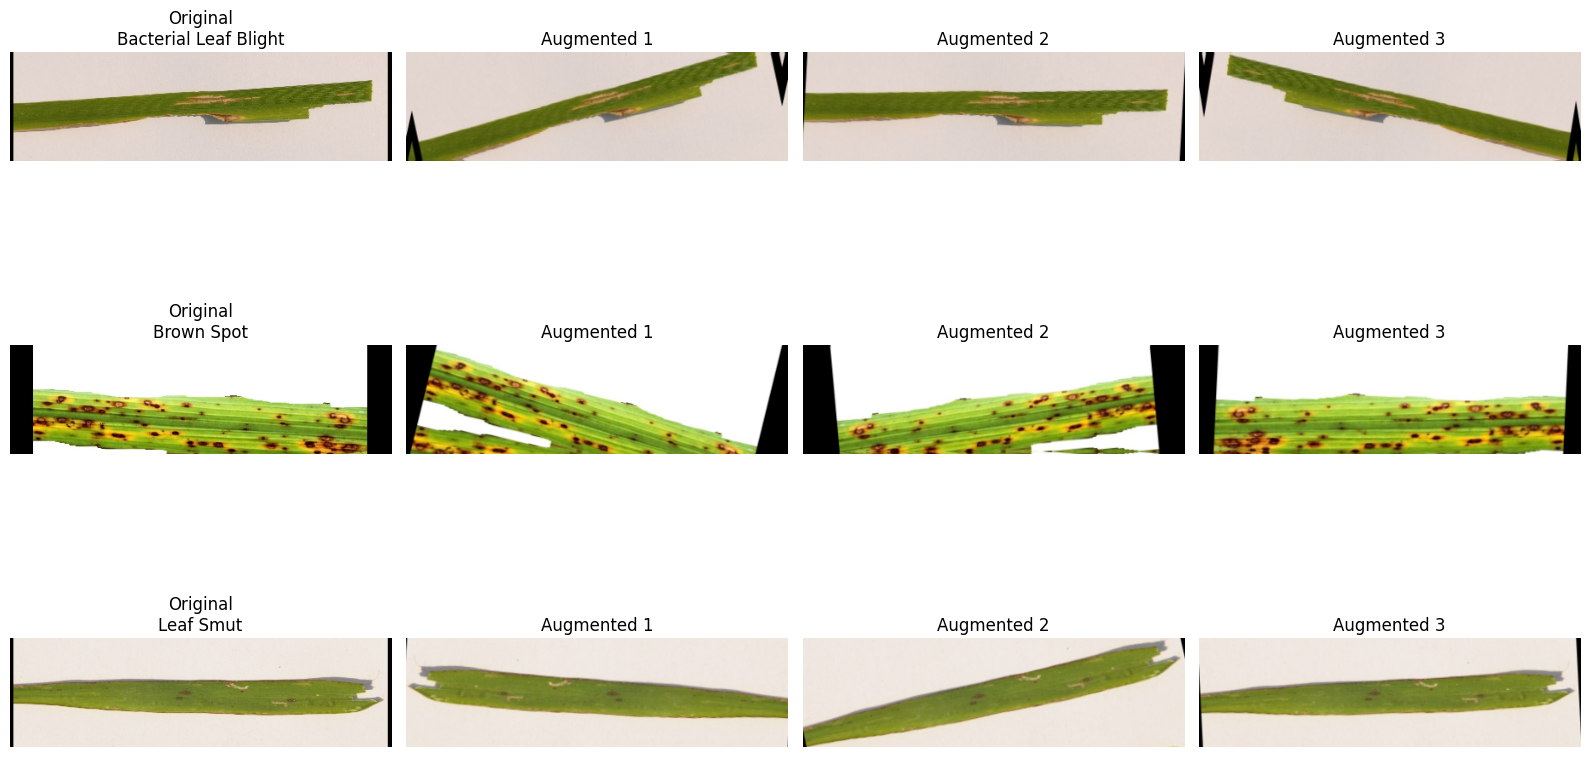

In [86]:
# Select one image from each class
sample_indices = [
    np.where(y_rect == class_id)[0][0]
    for class_id in range(3)
]

fig, axes = plt.subplots(3, 4, figsize=(16, 10))

for row, idx in enumerate(sample_indices):

    original = X_rect[idx]

    # Original image
    axes[row, 0].imshow(original)
    axes[row, 0].set_title(
        f"Original\n{label_encoder.inverse_transform([y_rect[idx]])[0]}"
    )
    axes[row, 0].axis("off")

    # Three augmented versions
    for col in range(1, 4):

        augmented = augmentation_model(
            tf.expand_dims(original, axis=0),
            training=True
        )[0].numpy()

        axes[row, col].imshow(
            np.clip(augmented, 0, 1)
        )
        axes[row, col].set_title(f"Augmented {col}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [87]:
# Store out-of-fold predictions
augmented_mobilenet_oof = np.zeros(len(y_rect), dtype=int)

augmented_mobilenet_results = []
augmented_mobilenet_c = []

param_grid = {
    "svm__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):

    print(f"\n{'='*50}")
    print(f"MobileNetV2 + Augmentation — Fold {fold_number}/5")
    print(f"{'='*50}")

    # Original training and validation features
    X_train_original = mobilenet_features[train_idx]
    X_val = mobilenet_features[val_idx]

    y_train = y_rect[train_idx]
    y_val = y_rect[val_idx]

    # Tune C using original training images only
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="linear"))
    ])

    inner_cv = StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    )

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="f1_macro",
        cv=inner_cv,
        n_jobs=-1
    )

    grid_search.fit(X_train_original, y_train)

    best_c = grid_search.best_params_["svm__C"]

    # Augment only the outer training images
    X_train_images = X_rect[train_idx]

    augmented_images = augmentation_model(
        X_train_images,
        training=True
    ).numpy()

    # Extract features from augmented images
    augmented_features = feature_extractor.predict(
        augmented_images,
        batch_size=8,
        verbose=0
    )

    # Combine original and augmented training features
    X_train_combined = np.concatenate(
        [X_train_original, augmented_features],
        axis=0
    )

    y_train_combined = np.concatenate(
        [y_train, y_train],
        axis=0
    )

    # Train final classifier
    final_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="linear", C=best_c))
    ])

    final_pipeline.fit(X_train_combined, y_train_combined)

    # Evaluate on untouched validation images
    predictions = final_pipeline.predict(X_val)

    augmented_mobilenet_oof[val_idx] = predictions
    augmented_mobilenet_c.append(best_c)

    accuracy = accuracy_score(y_val, predictions)
    macro_f1 = f1_score(y_val, predictions, average="macro")

    augmented_mobilenet_results.append({
        "Fold": fold_number,
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Best C": best_c,
        "Training Images": len(y_train_combined)
    })

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")
    print(f"Selected C: {best_c}")
    print(f"Training images after augmentation: {len(y_train_combined)}")

# Aggregate results
augmented_mobilenet_results_df = pd.DataFrame(
    augmented_mobilenet_results
)

print("\nFOLD-WISE RESULTS")
display(augmented_mobilenet_results_df)

print("\nMEAN CROSS-VALIDATION RESULTS")
print(
    "Mean Accuracy:",
    round(augmented_mobilenet_results_df["Accuracy"].mean(), 4)
)
print(
    "Mean Macro F1:",
    round(augmented_mobilenet_results_df["Macro F1"].mean(), 4)
)

print("\nOUT-OF-FOLD CLASSIFICATION REPORT")
print(
    classification_report(
        y_rect,
        augmented_mobilenet_oof,
        target_names=label_encoder.classes_
    )
)

print("OUT-OF-FOLD CONFUSION MATRIX")
print(confusion_matrix(y_rect, augmented_mobilenet_oof))


MobileNetV2 + Augmentation — Fold 1/5
Accuracy: 0.9583
Macro F1: 0.9582
Selected C: 0.01
Training images after augmentation: 190

MobileNetV2 + Augmentation — Fold 2/5
Accuracy: 0.9167
Macro F1: 0.9185
Selected C: 0.01
Training images after augmentation: 190

MobileNetV2 + Augmentation — Fold 3/5
Accuracy: 1.0000
Macro F1: 1.0000
Selected C: 0.01
Training images after augmentation: 190

MobileNetV2 + Augmentation — Fold 4/5
Accuracy: 0.9167
Macro F1: 0.9165
Selected C: 0.01
Training images after augmentation: 190

MobileNetV2 + Augmentation — Fold 5/5
Accuracy: 0.6522
Macro F1: 0.5760
Selected C: 0.001
Training images after augmentation: 192

FOLD-WISE RESULTS


,Fold,Accuracy,Macro F1,Best C,Training Images
0,1,0.958333,0.958170,0.010,190
1,2,0.916667,0.918519,0.010,190
2,3,1.000000,1.000000,0.010,190
3,4,0.916667,0.916503,0.010,190
4,5,0.652174,0.576035,0.001,192



MEAN CROSS-VALIDATION RESULTS
Mean Accuracy: 0.8888
Mean Macro F1: 0.8738

OUT-OF-FOLD CLASSIFICATION REPORT
                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.90      0.93      0.91        40
           Brown Spot       0.94      0.78      0.85        40
            Leaf Smut       0.84      0.97      0.90        39

             accuracy                           0.89       119
            macro avg       0.90      0.89      0.89       119
         weighted avg       0.90      0.89      0.89       119

OUT-OF-FOLD CONFUSION MATRIX
[[37  2  1]
 [ 3 31  6]
 [ 1  0 38]]


In [88]:
# Combine MobileNetV2 and EfficientNetB0 features

combined_features = np.concatenate(
    [mobilenet_features, efficientnet_features],
    axis=1
)

print("MobileNetV2 features:", mobilenet_features.shape)
print("EfficientNetB0 features:", efficientnet_features.shape)
print("Combined feature matrix:", combined_features.shape)
print("Data type:", combined_features.dtype)
print("All values finite:", np.isfinite(combined_features).all())

MobileNetV2 features: (119, 1280)
EfficientNetB0 features: (119, 1280)
Combined feature matrix: (119, 2560)
Data type: float32
All values finite: True


In [89]:
# Store out-of-fold predictions
combined_svm_oof = np.zeros(len(y_rect), dtype=int)

combined_svm_results = []
combined_selected_c = []

param_grid = {
    "svm__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):

    print(f"\n{'='*45}")
    print(f"Feature Fusion + Linear SVM — Fold {fold_number}/5")
    print(f"{'='*45}")

    X_train = combined_features[train_idx]
    X_val = combined_features[val_idx]

    y_train = y_rect[train_idx]
    y_val = y_rect[val_idx]

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="linear"))
    ])

    inner_cv = StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    )

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="f1_macro",
        cv=inner_cv,
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)

    best_model = grid_search.best_estimator_
    predictions = best_model.predict(X_val)

    combined_svm_oof[val_idx] = predictions

    accuracy = accuracy_score(y_val, predictions)
    macro_f1 = f1_score(y_val, predictions, average="macro")

    best_c = grid_search.best_params_["svm__C"]
    combined_selected_c.append(best_c)

    combined_svm_results.append({
        "Fold": fold_number,
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Best C": best_c
    })

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")
    print(f"Best C: {best_c}")

# Aggregate results
combined_svm_results_df = pd.DataFrame(combined_svm_results)

print("\nFOLD-WISE RESULTS")
display(combined_svm_results_df)

print("\nMEAN CROSS-VALIDATION RESULTS")
print(
    "Mean Accuracy:",
    round(combined_svm_results_df["Accuracy"].mean(), 4)
)
print(
    "Mean Macro F1:",
    round(combined_svm_results_df["Macro F1"].mean(), 4)
)

print("\nOUT-OF-FOLD CLASSIFICATION REPORT")
print(
    classification_report(
        y_rect,
        combined_svm_oof,
        target_names=label_encoder.classes_
    )
)

print("OUT-OF-FOLD CONFUSION MATRIX")
print(confusion_matrix(y_rect, combined_svm_oof))


Feature Fusion + Linear SVM — Fold 1/5
Accuracy: 1.0000
Macro F1: 1.0000
Best C: 0.001

Feature Fusion + Linear SVM — Fold 2/5
Accuracy: 0.9167
Macro F1: 0.9185
Best C: 0.01

Feature Fusion + Linear SVM — Fold 3/5
Accuracy: 1.0000
Macro F1: 1.0000
Best C: 0.001

Feature Fusion + Linear SVM — Fold 4/5
Accuracy: 0.9167
Macro F1: 0.9165
Best C: 0.01

Feature Fusion + Linear SVM — Fold 5/5
Accuracy: 0.7826
Macro F1: 0.7746
Best C: 0.001

FOLD-WISE RESULTS


,Fold,Accuracy,Macro F1,Best C
0,1,1.000000,1.000000,0.001
1,2,0.916667,0.918519,0.010
2,3,1.000000,1.000000,0.001
3,4,0.916667,0.916503,0.010
4,5,0.782609,0.774603,0.001



MEAN CROSS-VALIDATION RESULTS
Mean Accuracy: 0.9232
Mean Macro F1: 0.9219

OUT-OF-FOLD CLASSIFICATION REPORT
                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.90      0.95      0.93        40
           Brown Spot       0.97      0.85      0.91        40
            Leaf Smut       0.90      0.97      0.94        39

             accuracy                           0.92       119
            macro avg       0.93      0.92      0.92       119
         weighted avg       0.93      0.92      0.92       119

OUT-OF-FOLD CONFUSION MATRIX
[[38  1  1]
 [ 3 34  3]
 [ 1  0 38]]


In [90]:
from scipy.stats import binomtest

# Identify correct and incorrect predictions
mobilenet_correct = (linear_svm_oof == y_rect)
fusion_correct = (combined_svm_oof == y_rect)

# Compare where each model succeeds or fails
both_correct = np.sum(mobilenet_correct & fusion_correct)
both_wrong = np.sum(~mobilenet_correct & ~fusion_correct)

mobilenet_only_correct = np.sum(
    mobilenet_correct & ~fusion_correct
)

fusion_only_correct = np.sum(
    ~mobilenet_correct & fusion_correct
)

print("PAIRED MODEL COMPARISON")
print("Both models correct:", both_correct)
print("Both models wrong:", both_wrong)
print("Only MobileNetV2 correct:", mobilenet_only_correct)
print("Only Fusion correct:", fusion_only_correct)

# Exact McNemar test
discordant = mobilenet_only_correct + fusion_only_correct

if discordant > 0:
    test_result = binomtest(
        mobilenet_only_correct,
        n=discordant,
        p=0.5,
        alternative="two-sided"
    )

    print("\nEXACT McNEMAR TEST")
    print("Discordant predictions:", discordant)
    print("P-value:", round(test_result.pvalue, 4))
else:
    print("\nBoth models made identical correctness decisions.")

# Compare predictions by class
comparison_df = pd.DataFrame({
    "Actual": label_encoder.inverse_transform(y_rect),
    "MobileNetV2 Prediction": label_encoder.inverse_transform(
        linear_svm_oof
    ),
    "Fusion Prediction": label_encoder.inverse_transform(
        combined_svm_oof
    ),
    "MobileNetV2 Correct": mobilenet_correct,
    "Fusion Correct": fusion_correct
})

print("\nMODEL DISAGREEMENTS")
display(
    comparison_df[
        comparison_df["MobileNetV2 Prediction"]
        != comparison_df["Fusion Prediction"]
    ]
)

PAIRED MODEL COMPARISON
Both models correct: 108
Both models wrong: 7
Only MobileNetV2 correct: 2
Only Fusion correct: 2

EXACT McNEMAR TEST
Discordant predictions: 4
P-value: 1.0

MODEL DISAGREEMENTS


,Actual,MobileNetV2 Prediction,Fusion Prediction,MobileNetV2 Correct,Fusion Correct
22,Bacterial Leaf Blight,Brown Spot,Bacterial Leaf Blight,False,True
37,Bacterial Leaf Blight,Bacterial Leaf Blight,Leaf Smut,True,False
44,Brown Spot,Leaf Smut,Brown Spot,False,True
73,Brown Spot,Brown Spot,Bacterial Leaf Blight,True,False


In [91]:
# Collect all model experiments

model_experiments = [
    {
        "Model": "MobileNetV2 + Linear SVM",
        "Results": mobilenet_results_df,
        "Predictions": linear_svm_oof
    },
    {
        "Model": "MobileNetV2 + RBF SVM",
        "Results": mobilenet_rbf_results_df,
        "Predictions": mobilenet_rbf_oof
    },
    {
        "Model": "EfficientNetB0 + Linear SVM",
        "Results": efficientnet_svm_results_df,
        "Predictions": efficientnet_svm_oof
    },
    {
        "Model": "EfficientNetB0 + RBF SVM",
        "Results": efficientnet_rbf_results_df,
        "Predictions": efficientnet_rbf_oof
    },
    {
        "Model": "MobileNetV2 + EfficientNetB0 Fusion",
        "Results": combined_svm_results_df,
        "Predictions": combined_svm_oof
    },
    {
        "Model": "MobileNetV2 + Augmentation",
        "Results": augmented_mobilenet_results_df,
        "Predictions": augmented_mobilenet_oof
    }
]

comparison_rows = []

for experiment in model_experiments:

    predictions = experiment["Predictions"]
    results = experiment["Results"]

    comparison_rows.append({
        "Model": experiment["Model"],
        "Mean CV Accuracy": results["Accuracy"].mean(),
        "Mean CV Macro F1": results["Macro F1"].mean(),
        "OOF Accuracy": accuracy_score(y_rect, predictions),
        "OOF Macro F1": f1_score(
            y_rect, predictions, average="macro"
        )
    })

final_model_comparison = pd.DataFrame(comparison_rows)

final_model_comparison = final_model_comparison.sort_values(
    by="Mean CV Macro F1",
    ascending=False
).reset_index(drop=True)

display(
    final_model_comparison.style.format({
        "Mean CV Accuracy": "{:.2%}",
        "Mean CV Macro F1": "{:.2%}",
        "OOF Accuracy": "{:.2%}",
        "OOF Macro F1": "{:.2%}"
    })
)

NameError: name 'mobilenet_results_df' is not defined

In [92]:
# Find variables related to MobileNetV2 experiments

for name in sorted(globals()):
    if "mobilenet" in name.lower() or "linear_svm" in name.lower():
        print(name)

MobileNetV2
augmented_mobilenet_c
augmented_mobilenet_oof
augmented_mobilenet_results
augmented_mobilenet_results_df
linear_svm_oof
mobilenet_correct
mobilenet_cv_results
mobilenet_features
mobilenet_only_correct
mobilenet_oof
mobilenet_rbf_oof
mobilenet_rbf_params
mobilenet_rbf_results
mobilenet_rbf_results_df
run_mobilenet_cv


In [93]:
print(type(mobilenet_cv_results))
print(mobilenet_cv_results)

<class 'pandas.DataFrame'>
   Fold  Accuracy  Macro_F1  Best_Val_Loss  Epochs_Trained
0     1  0.333333  0.239506       1.077368              30
1     2  0.416667  0.416667       1.053429              30
2     3  0.333333  0.335897       1.068592              30
3     4  0.458333  0.414006       1.053282              30
4     5  0.478261  0.469697       1.066050              30


In [94]:
print(type(nested_svm_results))
print(nested_svm_results)

<class 'list'>
[{'Fold': 1, 'Accuracy': 0.9583333333333334, 'Macro F1': 0.9581699346405229, 'Best C': 0.01}, {'Fold': 2, 'Accuracy': 0.9583333333333334, 'Macro F1': 0.9581699346405229, 'Best C': 0.01}, {'Fold': 3, 'Accuracy': 1.0, 'Macro F1': 1.0, 'Best C': 0.01}, {'Fold': 4, 'Accuracy': 0.9166666666666666, 'Macro F1': 0.9165032679738562, 'Best C': 0.01}, {'Fold': 5, 'Accuracy': 0.782608695652174, 'Macro F1': 0.7695906432748538, 'Best C': 0.001}]


In [95]:
# Original MobileNetV2 + Linear SVM results
mobilenet_linear_results_df = pd.DataFrame(nested_svm_results)

# Collect all experiments
model_experiments = [
    {
        "Model": "MobileNetV2 + Linear SVM",
        "Results": mobilenet_linear_results_df,
        "F1_Column": "Macro F1",
        "Predictions": linear_svm_oof
    },
    {
        "Model": "MobileNetV2 + RBF SVM",
        "Results": mobilenet_rbf_results_df,
        "F1_Column": "Macro F1",
        "Predictions": mobilenet_rbf_oof
    },
    {
        "Model": "EfficientNetB0 + Linear SVM",
        "Results": efficientnet_svm_results_df,
        "F1_Column": "Macro F1",
        "Predictions": efficientnet_svm_oof
    },
    {
        "Model": "EfficientNetB0 + RBF SVM",
        "Results": efficientnet_rbf_results_df,
        "F1_Column": "Macro F1",
        "Predictions": efficientnet_rbf_oof
    },
    {
        "Model": "MobileNetV2 + EfficientNetB0 Fusion",
        "Results": combined_svm_results_df,
        "F1_Column": "Macro F1",
        "Predictions": combined_svm_oof
    },
    {
        "Model": "MobileNetV2 + Augmentation",
        "Results": augmented_mobilenet_results_df,
        "F1_Column": "Macro F1",
        "Predictions": augmented_mobilenet_oof
    }
]

comparison_rows = []

for experiment in model_experiments:

    results = experiment["Results"]
    predictions = experiment["Predictions"]

    comparison_rows.append({
        "Model": experiment["Model"],
        "Mean CV Accuracy": results["Accuracy"].mean(),
        "Mean CV Macro F1": results[experiment["F1_Column"]].mean(),
        "OOF Accuracy": accuracy_score(y_rect, predictions),
        "OOF Macro F1": f1_score(
            y_rect, predictions, average="macro"
        )
    })

final_model_comparison = pd.DataFrame(comparison_rows)

final_model_comparison = final_model_comparison.sort_values(
    by="Mean CV Macro F1",
    ascending=False
).reset_index(drop=True)

display(
    final_model_comparison.style.format({
        "Mean CV Accuracy": "{:.2%}",
        "Mean CV Macro F1": "{:.2%}",
        "OOF Accuracy": "{:.2%}",
        "OOF Macro F1": "{:.2%}"
    })
)

,Model,Mean CV Accuracy,Mean CV Macro F1,OOF Accuracy,OOF Macro F1
0,MobileNetV2 + EfficientNetB0 Fusion,92.32%,92.19%,92.44%,92.39%
1,MobileNetV2 + Linear SVM,92.32%,92.05%,92.44%,92.38%
2,EfficientNetB0 + RBF SVM,91.52%,91.48%,91.60%,91.60%
3,EfficientNetB0 + Linear SVM,91.49%,91.35%,91.60%,91.59%
4,MobileNetV2 + RBF SVM,91.49%,91.32%,91.60%,91.56%
5,MobileNetV2 + Augmentation,88.88%,87.38%,89.08%,88.92%


In [96]:
final_model_comparison.to_csv(
    "rice_leaf_model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [97]:
print("Selected C values across folds:")
print([result["Best C"] for result in nested_svm_results])

print("\nMost frequently selected C:")
print(pd.Series(
    [result["Best C"] for result in nested_svm_results]
).mode().iloc[0])

Selected C values across folds:
[0.01, 0.01, 0.01, 0.01, 0.001]

Most frequently selected C:
0.01


In [98]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
import joblib

# Build the final classification pipeline
final_svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="linear",
        C=0.01,
        probability=True,
        random_state=42
    ))
])

# Train using all 119 extracted feature vectors
final_svm_model.fit(mobilenet_features, y)

print("Final model trained successfully!")
print("Training samples:", mobilenet_features.shape[0])
print("Feature dimensions:", mobilenet_features.shape[1])
print("Selected C:", final_svm_model.named_steps["svm"].C)
print("Kernel:", final_svm_model.named_steps["svm"].kernel)
print("Classes:", label_encoder.classes_)

Final model trained successfully!
Training samples: 119
Feature dimensions: 1280
Selected C: 0.01
Kernel: linear
Classes: ['Bacterial Leaf Blight' 'Brown Spot' 'Leaf Smut']


C:\Users\Pavan\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [99]:
import joblib

joblib.dump(
    final_svm_model,
    "rice_leaf_final_svm.joblib"
)

print("Final SVM model saved successfully!")

Final SVM model saved successfully!


In [100]:
feature_extractor.save(
    "rice_leaf_mobilenet_feature_extractor.keras"
)

print("MobileNetV2 feature extractor saved successfully!")

MobileNetV2 feature extractor saved successfully!


In [101]:
def predict_rice_disease(image_path):

    # Read image
    image = tf.io.read_file(image_path)
    image = tf.io.decode_jpeg(image, channels=3)

    # Resize while preserving aspect ratio
    image = tf.image.resize_with_pad(
        image,
        target_height=128,
        target_width=448
    )

    # Normalize
    image = tf.cast(image, tf.float32) / 255.0

    # Add batch dimension
    image = tf.expand_dims(image, axis=0)

    # Extract MobileNetV2 features
    features = feature_extractor.predict(
        image,
        verbose=0
    )

    # Predict disease class
    prediction = final_svm_model.predict(features)[0]

    # Convert encoded label into original class name
    disease_name = label_encoder.inverse_transform(
        [prediction]
    )[0]

    return disease_name


print("Prediction function created successfully!")

Prediction function created successfully!


In [102]:
# Select one image from the dataset
test_image_path = X[0]

# Get actual class
actual_class = label_encoder.inverse_transform(
    [y[0]]
)[0]

# Predict disease
predicted_class = predict_rice_disease(test_image_path)

print("Image:", os.path.basename(test_image_path))
print("Actual disease:", actual_class)
print("Predicted disease:", predicted_class)
print("Prediction correct:", actual_class == predicted_class)

Image: DSC_0365.JPG
Actual disease: Bacterial Leaf Blight
Predicted disease: Bacterial Leaf Blight
Prediction correct: True


In [103]:
all_predictions = []

for image_path in X:
    predicted_class = predict_rice_disease(image_path)
    all_predictions.append(predicted_class)

actual_classes = label_encoder.inverse_transform(y)

prediction_check = pd.DataFrame({
    "Filename": [os.path.basename(p) for p in X],
    "Actual Class": actual_classes,
    "Predicted Class": all_predictions
})

prediction_check["Correct"] = (
    prediction_check["Actual Class"] ==
    prediction_check["Predicted Class"]
)

print("Total images:", len(prediction_check))
print("Correct predictions:", prediction_check["Correct"].sum())
print("Incorrect predictions:", (~prediction_check["Correct"]).sum())

display(prediction_check.head(10))

Total images: 119
Correct predictions: 119
Incorrect predictions: 0


,Filename,Actual Class,Predicted Class,Correct
0,DSC_0365.JPG,Bacterial Leaf Blight,Bacterial Leaf Blight,True
1,DSC_0366.jpg,Bacterial Leaf Blight,Bacterial Leaf Blight,True
2,DSC_0367.JPG,Bacterial Leaf Blight,Bacterial Leaf Blight,True
3,DSC_0370.jpg,Bacterial Leaf Blight,Bacterial Leaf Blight,True
4,DSC_0372.JPG,Bacterial Leaf Blight,Bacterial Leaf Blight,True
5,DSC_0373.JPG,Bacterial Leaf Blight,Bacterial Leaf Blight,True
6,DSC_0374.JPG,Bacterial Leaf Blight,Bacterial Leaf Blight,True
7,DSC_0375.JPG,Bacterial Leaf Blight,Bacterial Leaf Blight,True
8,DSC_0376.JPG,Bacterial Leaf Blight,Bacterial Leaf Blight,True
9,DSC_0377.JPG,Bacterial Leaf Blight,Bacterial Leaf Blight,True


In [104]:
# Compare out-of-fold predictions with actual labels

oof_correct = linear_svm_oof == y_rect

print("Out-of-fold evaluation")
print("----------------------")
print("Total images:", len(y_rect))
print("Correct predictions:", np.sum(oof_correct))
print("Incorrect predictions:", np.sum(~oof_correct))
print(
    "OOF Accuracy:",
    f"{accuracy_score(y_rect, linear_svm_oof):.2%}"
)

# Create error analysis dataframe
oof_errors = dataset_df.loc[
    ~oof_correct,
    ["Filename", "Class", "Width", "Height", "Aspect_Ratio"]
].copy()

oof_errors["Predicted Class"] = label_encoder.inverse_transform(
    linear_svm_oof[~oof_correct]
)

display(oof_errors)

Out-of-fold evaluation
----------------------
Total images: 119
Correct predictions: 110
Incorrect predictions: 9
OOF Accuracy: 92.44%


,Filename,Class,Width,Height,Aspect_Ratio,Predicted Class
22,DSC_0392.JPG,Bacterial Leaf Blight,3081,897,3.434783,Brown Spot
38,DSC_0702.jpg,Bacterial Leaf Blight,3081,897,3.434783,Brown Spot
44,DSC_0106.jpg,Brown Spot,1504,323,4.656347,Leaf Smut
55,DSC_0117.jpg,Brown Spot,467,104,4.490385,Leaf Smut
58,DSC_0121.jpg,Brown Spot,1200,900,1.333333,Leaf Smut
59,DSC_0292.JPG,Brown Spot,3081,897,3.434783,Bacterial Leaf Blight
74,DSC_0329.jpg,Brown Spot,3081,897,3.434783,Leaf Smut
78,DSC_0391.jpg,Brown Spot,3081,897,3.434783,Bacterial Leaf Blight
111,DSC_0509.jpg,Leaf Smut,3081,897,3.434783,Bacterial Leaf Blight


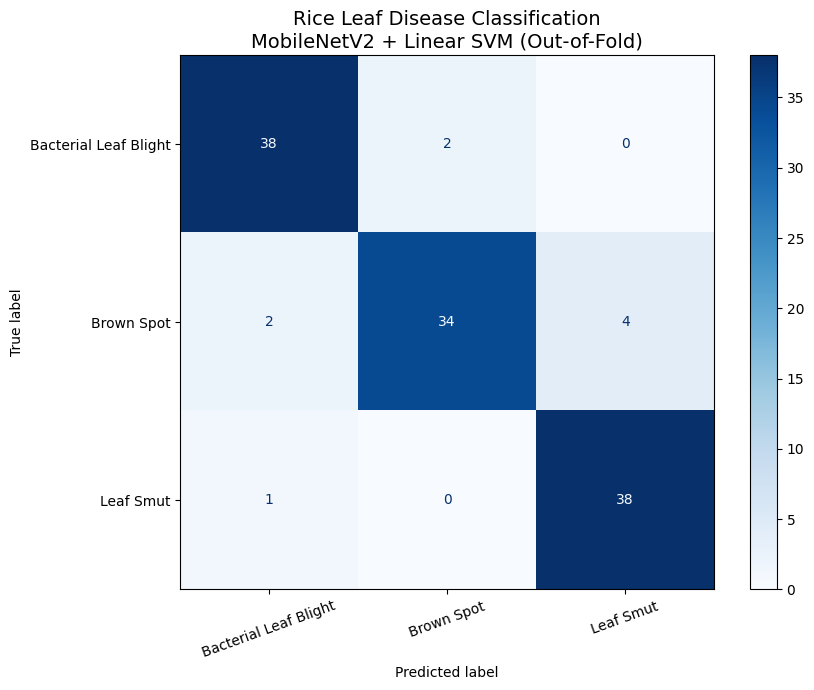

In [108]:
from sklearn.metrics import ConfusionMatrixDisplay

class_names = label_encoder.classes_

fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay.from_predictions(
    y_rect,
    linear_svm_oof,
    display_labels=class_names,
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title(
    "Rice Leaf Disease Classification\n"
    "MobileNetV2 + Linear SVM (Out-of-Fold)",
    fontsize=14
)

plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(
    "rice_leaf_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [109]:
from sklearn.metrics import classification_report

final_report = classification_report(
    y_rect,
    linear_svm_oof,
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

final_report_df = pd.DataFrame(final_report).transpose()

display(
    final_report_df.style.format({
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1-score": "{:.4f}"
    })
)

final_report_df.to_csv(
    "rice_leaf_classification_report.csv"
)

print("Classification report saved successfully!")

,precision,recall,f1-score,support
Bacterial Leaf Blight,0.9268,0.9500,0.9383,40.000000
Brown Spot,0.9444,0.8500,0.8947,40.000000
Leaf Smut,0.9048,0.9744,0.9383,39.000000
accuracy,0.9244,0.9244,0.9244,0.924370
macro avg,0.9253,0.9248,0.9238,119.000000
weighted avg,0.9255,0.9244,0.9236,119.000000


Classification report saved successfully!


In [110]:
project_summary = {
    "Dataset Images": 119,
    "Number of Classes": 3,
    "Training Image Size": "128 x 448",
    "Feature Extractor": "MobileNetV2 (ImageNet)",
    "Feature Dimensions": 1280,
    "Classifier": "Linear SVM",
    "Selected C": 0.01,
    "Mean CV Accuracy": 0.9232,
    "Mean CV Macro F1": 0.9205,
    "OOF Accuracy": 0.9244,
    "OOF Macro F1": 0.9238,
    "Correct OOF Predictions": 110,
    "Incorrect OOF Predictions": 9
}

project_summary_df = pd.DataFrame(
    list(project_summary.items()),
    columns=["Metric", "Value"]
)

display(project_summary_df)

project_summary_df.to_csv(
    "rice_leaf_project_summary.csv",
    index=False
)

print("Project summary saved successfully!")

,Metric,Value
0,Dataset Images,119
1,Number of Classes,3
2,Training Image Size,128 x 448
3,Feature Extractor,MobileNetV2 (ImageNet)
4,Feature Dimensions,1280
5,Classifier,Linear SVM
6,Selected C,0.01
7,Mean CV Accuracy,0.9232
8,Mean CV Macro F1,0.9205
9,OOF Accuracy,0.9244


Project summary saved successfully!


In [111]:
augmentation_analysis = pd.DataFrame([
    {
        "Model": "Scratch CNN",
        "Without Augmentation Accuracy": 0.6138,
        "With Augmentation Accuracy": 0.5536,
        "Accuracy Change": 0.5536 - 0.6138,
        "Without Augmentation Macro F1": 0.5997,
        "With Augmentation Macro F1": 0.5265,
        "Macro F1 Change": 0.5265 - 0.5997
    },
    {
        "Model": "MobileNetV2 + Linear SVM",
        "Without Augmentation Accuracy": 0.9232,
        "With Augmentation Accuracy": 0.8888,
        "Accuracy Change": 0.8888 - 0.9232,
        "Without Augmentation Macro F1": 0.9205,
        "With Augmentation Macro F1": 0.8738,
        "Macro F1 Change": 0.8738 - 0.9205
    }
])

display(
    augmentation_analysis.style.format({
        col: "{:.2%}"
        for col in augmentation_analysis.columns
        if col != "Model"
    })
)

augmentation_analysis.to_csv(
    "rice_leaf_augmentation_analysis.csv",
    index=False
)

print("Augmentation analysis saved successfully!")

,Model,Without Augmentation Accuracy,With Augmentation Accuracy,Accuracy Change,Without Augmentation Macro F1,With Augmentation Macro F1,Macro F1 Change
0,Scratch CNN,61.38%,55.36%,-6.02%,59.97%,52.65%,-7.32%
1,MobileNetV2 + Linear SVM,92.32%,88.88%,-3.44%,92.05%,87.38%,-4.67%


Augmentation analysis saved successfully!


In [112]:
expected_files = [
    "rice_leaf_final_svm.joblib",
    "rice_leaf_mobilenet_feature_extractor.keras",
    "rice_leaf_model_comparison.csv",
    "rice_leaf_confusion_matrix.png",
    "rice_leaf_classification_report.csv",
    "rice_leaf_project_summary.csv",
    "rice_leaf_augmentation_analysis.csv"
]

print("PROJECT DELIVERABLE CHECK")
print("=" * 45)

for filename in expected_files:
    exists = os.path.exists(filename)
    status = "SAVED" if exists else "MISSING"
    print(f"{filename}: {status}")

print("=" * 45)

missing_files = [
    filename for filename in expected_files
    if not os.path.exists(filename)
]

print("Missing files:", len(missing_files))

PROJECT DELIVERABLE CHECK
rice_leaf_final_svm.joblib: SAVED
rice_leaf_mobilenet_feature_extractor.keras: SAVED
rice_leaf_model_comparison.csv: SAVED
rice_leaf_confusion_matrix.png: SAVED
rice_leaf_classification_report.csv: SAVED
rice_leaf_project_summary.csv: SAVED
rice_leaf_augmentation_analysis.csv: SAVED
Missing files: 0


In [113]:
joblib.dump(
    label_encoder,
    "rice_leaf_label_encoder.joblib"
)

print("Label encoder saved successfully!")
print("\nClass mapping:")

for index, class_name in enumerate(label_encoder.classes_):
    print(f"{index} -> {class_name}")

Label encoder saved successfully!

Class mapping:
0 -> Bacterial Leaf Blight
1 -> Brown Spot
2 -> Leaf Smut


In [114]:
# Load saved components
loaded_feature_extractor = tf.keras.models.load_model(
    "rice_leaf_mobilenet_feature_extractor.keras"
)

loaded_svm_model = joblib.load(
    "rice_leaf_final_svm.joblib"
)

loaded_label_encoder = joblib.load(
    "rice_leaf_label_encoder.joblib"
)

print("All components loaded successfully!")

# Test using the previously selected image
test_image_path = X[0]

image = tf.io.read_file(test_image_path)
image = tf.io.decode_jpeg(image, channels=3)
image = tf.image.resize_with_pad(image, 128, 448)
image = tf.cast(image, tf.float32) / 255.0
image = tf.expand_dims(image, axis=0)

features = loaded_feature_extractor.predict(
    image, verbose=0
)

prediction = loaded_svm_model.predict(features)[0]

predicted_disease = loaded_label_encoder.inverse_transform(
    [prediction]
)[0]

print("\nReloaded model prediction:")
print("Image:", os.path.basename(test_image_path))
print("Predicted disease:", predicted_disease)

All components loaded successfully!

Reloaded model prediction:
Image: DSC_0365.JPG
Predicted disease: Bacterial Leaf Blight


In [115]:
import os

files_to_check = [
    "rice_leaf_final_svm.joblib",
    "rice_leaf_mobilenet_feature_extractor.keras",
    "rice_leaf_label_encoder.joblib"
]

print("MODEL ARTIFACT SIZES")
print("=" * 45)

for filename in files_to_check:
    size_mb = os.path.getsize(filename) / (1024 ** 2)
    print(f"{filename}: {size_mb:.2f} MB")

MODEL ARTIFACT SIZES
rice_leaf_final_svm.joblib: 0.89 MB
rice_leaf_mobilenet_feature_extractor.keras: 9.17 MB
rice_leaf_label_encoder.joblib: 0.00 MB


In [116]:
import os

project_dirs = [
    "Rice-Leaf-Disease-Detection/data",
    "Rice-Leaf-Disease-Detection/models",
    "Rice-Leaf-Disease-Detection/results",
    "Rice-Leaf-Disease-Detection/notebooks"
]

for directory in project_dirs:
    os.makedirs(directory, exist_ok=True)

print("Project directory structure created!")

for directory in project_dirs:
    print(directory)

Project directory structure created!
Rice-Leaf-Disease-Detection/data
Rice-Leaf-Disease-Detection/models
Rice-Leaf-Disease-Detection/results
Rice-Leaf-Disease-Detection/notebooks


In [117]:
import shutil
import os

# Model files
model_files = [
    "rice_leaf_final_svm.joblib",
    "rice_leaf_mobilenet_feature_extractor.keras",
    "rice_leaf_label_encoder.joblib"
]

# Result files
result_files = [
    "rice_leaf_model_comparison.csv",
    "rice_leaf_confusion_matrix.png",
    "rice_leaf_classification_report.csv",
    "rice_leaf_project_summary.csv",
    "rice_leaf_augmentation_analysis.csv"
]

# Copy models
for filename in model_files:
    shutil.copy2(
        filename,
        os.path.join("Rice-Leaf-Disease-Detection", "models", filename)
    )

# Copy results
for filename in result_files:
    shutil.copy2(
        filename,
        os.path.join("Rice-Leaf-Disease-Detection", "results", filename)
    )

print("All model and result files copied successfully!")

All model and result files copied successfully!


In [118]:
for folder in ["models", "results"]:
    folder_path = os.path.join("Rice-Leaf-Disease-Detection", folder)

    print(f"\n{folder.upper()}")
    for filename in os.listdir(folder_path):
        print("✓", filename)


MODELS
✓ rice_leaf_final_svm.joblib
✓ rice_leaf_label_encoder.joblib
✓ rice_leaf_mobilenet_feature_extractor.keras

RESULTS
✓ rice_leaf_augmentation_analysis.csv
✓ rice_leaf_classification_report.csv
✓ rice_leaf_confusion_matrix.png
✓ rice_leaf_model_comparison.csv
✓ rice_leaf_project_summary.csv


In [119]:
data_readme = """
# Dataset Information

## Project Dataset

Rice Leaf Disease Detection dataset used for this project.

## Dataset Statistics

| Disease Class | Number of Images |
|---|---:|
| Bacterial Leaf Blight | 40 |
| Brown Spot | 40 |
| Leaf Smut | 39 |
| **Total** | **119** |

## Dataset Structure

The original dataset contains three disease-class folders:

- Bacterial Leaf Blight
- Brown Spot
- Leaf Smut

## Dataset Discrepancy

The institute project description refers to 120 images and mentions
Leaf Blast. However, the supplied dataset contains 119 images and
uses Leaf Smut as the third class.

The actual dataset labels were retained for model training.
No artificial image was created to compensate for the missing sample.

## Preprocessing

- Image decoding: JPEG, RGB
- Resizing: 128 x 448 pixels
- Aspect ratio: preserved using padding
- Pixel normalization: [0, 1]
- Feature extraction: ImageNet-pretrained MobileNetV2

## Data Availability

The original dataset is not included in this repository.
Place the dataset in the expected local folder structure before
running the notebook.
"""

data_readme_path = os.path.join(
    "Rice-Leaf-Disease-Detection",
    "data",
    "README.md"
)

with open(data_readme_path, "w", encoding="utf-8") as file:
    file.write(data_readme)

print("Dataset README created successfully!")

Dataset README created successfully!


In [121]:
import sys
import tensorflow as tf
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import PIL
import cv2
import joblib

print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Pillow:", PIL.__version__)
print("OpenCV:", cv2.__version__)
print("Joblib:", joblib.__version__)

Python: 3.14.3 (tags/v3.14.3:323c59a, Feb  3 2026, 16:04:56) [MSC v.1944 64 bit (AMD64)]
TensorFlow: 2.22.0-rc0
NumPy: 2.4.2
Pandas: 3.0.3
Scikit-learn: 1.9.0
Matplotlib: 3.10.8
Pillow: 12.1.1
OpenCV: 5.0.0
Joblib: 1.5.3
